# Predicting Missense Variant Pathogenicity — Phase 2: Models, Failure Analysis and Final Test

**CMPS 261 — Machine Learning, Fall 2026 · Section L2**
Mohamad Ali Al Kammouni · Mohamad Malek Hotait

This notebook continues `01_phase1_baseline.ipynb` (data, features, splits, initial baseline).
It covers everything after the progress report. As in Phase 1, the heavy lifting is done by the
scripts in `scripts/`; this notebook explains each decision, checks the outputs, and adds the
diagnostics and figures.

**Contents**
1. Setup and the Phase 2 pipeline
2. Level 1: gradient-boosted trees on the swap features
3. Protein sequences from UniProt, and length / position features
4. Level 2: ESM-2 protein language model
5. Interpretability of the Level 1 trees
6. Failure analysis and mitigations (validation part)
7. Final evaluation on the test part (used once)
8. Complexity analysis
9. Using the released model
10. Conclusions
11. Appendix: complete source code of the Phase 2 scripts

## 1. Setup and the Phase 2 pipeline

Run this notebook from the repository with the `clinvar` environment selected as the kernel.
Phase 1 must have been run first (`data/processed/variants.parquet`, `features_swap.parquet`,
`data/splits/splits.parquet`).

`RUN_PIPELINE = True` re-runs every Phase 2 script in order (about an hour on our laptop:
UniProt download, ESM-2 on an NVIDIA GPU for about 4 minutes, then CPU model fitting). With
`False`, the notebook reads the outputs the scripts already produced.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

# Locate the repository root whether the notebook is opened from notebooks/ or the root.
ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent
REPORTS, FIGURES = ROOT / "reports", ROOT / "reports" / "figures"
PROC, MODELS = ROOT / "data" / "processed", ROOT / "models"
ESM_MODEL = "esm2_t12_35M_UR50D"   # smallest ESM-2, 35M parameters
TAG = f"esm_{ESM_MODEL}"

RUN_PIPELINE = False

def show_md(path):
    """Display one of the markdown reports written by the scripts."""
    display(Markdown((REPORTS / path).read_text(encoding="utf-8")))

pd.set_option("display.max_columns", 30)
print("Repository root:", ROOT)

Repository root: C:\Users\malii\Desktop\Fall26\ML\Project\project\clinvar-pathogenicity


In [2]:
# Each step, in order, with its arguments. Every script checks row order between files and
# stops with an error instead of silently mixing variants up.
PIPELINE = [
    ("run_gbm.py", []),                                # Level 1 trees, swap features
    ("fetch_uniprot.py", []),                          # UniProt reviewed human proteome
    ("map_sequences.py", []),                          # variant -> protein, residue check
    ("run_gbm_position.py", []),                       # + protein length and position
    ("esm_scores.py", ["--model", ESM_MODEL]),         # ESM-2 forward passes (GPU)
    ("run_esm_models.py", ["--model", ESM_MODEL]),     # zero-shot, embedding + LR, trees + ESM
    ("failure_analysis.py", ["--model", ESM_MODEL]),   # slices, recalibration, abstention
    ("final_test.py", ["--model", ESM_MODEL]),         # the one and only use of the test part
]

if RUN_PIPELINE:
    for script, args in PIPELINE:
        print(f"=== {script} ===")
        result = subprocess.run([sys.executable, str(ROOT / "scripts" / script), *args],
                                cwd=ROOT, capture_output=True, text=True)
        print(result.stdout[-1500:])
        if result.returncode != 0:
            raise RuntimeError(result.stderr)
else:
    print("Using existing outputs. Set RUN_PIPELINE = True to regenerate everything.")

Using existing outputs. Set RUN_PIPELINE = True to regenerate everything.


## 2. Level 1: gradient-boosted trees on the swap features

`scripts/run_gbm.py` trains `HistGradientBoostingClassifier` (200 iterations) on the same 16 swap
features as the Phase 1 logistic regression, on both splits and all 5 seeds.

**Tuning.** Grid over learning rate {0.05, 0.1}, leaves {7, 31} and minimum leaf size {20, 200},
chosen by 5-fold `GroupKFold` by gene inside the training part only, scored by AUPRC (the classes
are imbalanced, 29.6% pathogenic). The validation part is only used to report results.

**Diagnostic: the swap lookup table.** The 16 swap features depend only on the pair (original,
new amino acid), so they take just 150 distinct values in our data. The best any swap-only model
can do is to predict, for each swap, its pathogenic share in training. We compute that lookup
table as a ceiling.

In [3]:
show_md("gbm_summary.md")

# Gradient-boosted trees on the swap features (validation part, 5 seeds)

| Model | Split | AUROC | AUPRC | BRIER | ECE | PER GENE AUROC |
|---|---|---|---|---|---|---|
| logreg | random | 0.731 ± 0.005 | 0.529 ± 0.005 | 0.178 ± 0.001 | - | 0.714 ± 0.005 |
| logreg | gene | 0.732 ± 0.005 | 0.530 ± 0.008 | 0.178 ± 0.001 | - | 0.724 ± 0.004 |
| gbm | random | 0.764 ± 0.005 | 0.583 ± 0.004 | 0.168 ± 0.001 | 0.008 ± 0.002 | 0.736 ± 0.008 |
| gbm | gene | 0.764 ± 0.003 | 0.574 ± 0.007 | 0.169 ± 0.001 | 0.011 ± 0.003 | 0.742 ± 0.009 |
| swap_lookup | random | 0.764 ± 0.005 | 0.583 ± 0.004 | 0.168 ± 0.001 | 0.008 ± 0.002 | 0.736 ± 0.008 |
| swap_lookup | gene | 0.764 ± 0.003 | 0.574 ± 0.007 | 0.169 ± 0.001 | 0.011 ± 0.003 | 0.740 ± 0.010 |

ECE for logreg was computed only for seed 0 in the notebook (0.018).

## Gradient-boosted trees: settings and cost

- Grid: {'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [7, 31], 'min_samples_leaf': [20, 200]}, max_iter=200, tuned by 5-fold GroupKFold on train, scored by AUPRC
- Chosen (learning_rate, max_leaf_nodes, min_samples_leaf) across the 10 runs: 0.1, 31.0, 200.0 x3; 0.1, 7.0, 200.0 x2; 0.1, 7.0, 20.0 x2; 0.05, 31.0, 20.0 x1; 0.1, 31.0, 20.0 x1; 0.05, 31.0, 200.0 x1
- Training time incl. tuning: 18.9 s on average (wall-clock, parallel; depends on the machine)
- Inference: 3.764 ms per 1,000 variants
- Model size: 490 KB
- Predicted probabilities range 0.02 to 0.88

swap_lookup is a diagnostic: the best any swap-only model can do on this data.


In [4]:
feats = pd.read_parquet(PROC / "features_swap.parquet")
swap_cols = [c for c in feats.columns if c not in ("variation_id", "gene", "label")]
print("Distinct swap feature vectors:", len(feats[swap_cols].drop_duplicates()))

Distinct swap feature vectors: 150


**Reading.** The trees match the lookup table to three decimals (AUROC 0.764 on both splits): they
have extracted everything the swap features can give, and the logistic regression (0.73)
underfits that space. Any further gain must come from information about *where* in *which*
protein the swap happens. The near-identical random and gene results confirm that swap features
carry no gene identity.

## 3. Protein sequences from UniProt, and length / position features

`scripts/fetch_uniprot.py` downloads the reviewed (Swiss-Prot) human proteome once and records the
release and an MD5 checksum, like the ClinVar snapshot. `scripts/map_sequences.py` attaches each
variant to its gene's protein.

**Why a residue check.** ClinVar positions come from a RefSeq transcript, which is not always
UniProt's canonical isoform. A variant is accepted only if the UniProt residue at ClinVar's
position equals ClinVar's original amino acid; otherwise the position would point to the wrong
residue silently.

In [5]:
display(pd.Series(json.loads((REPORTS / "uniprot_snapshot.json").read_text())).to_frame("value"))
show_md("mapping_summary.md")

,value
source_url,https://rest.uniprot.org/uniprotkb/stream?quer...
uniprot_release,2026_04
downloaded_at,2026-11-20T10:49:27
md5,1eb653edf190b3587ac72feb1f23be4b
rows,20429
rows_with_gene_name,20281
genes_with_more_than_one_entry,93


# Mapping variants to UniProt sequences

| Status | Variants | Share | % pathogenic | Genes |
|---|---:|---:|---:|---:|
| mapped | 185,104 | 92.8% | 30.5% | 14,731 |
| residue mismatch | 12,774 | 6.4% | 18.2% | 1,216 |
| position beyond protein length | 848 | 0.4% | 9.1% | 250 |
| gene not in UniProt | 648 | 0.3% | 18.7% | 119 |

- Mapped proteins longer than 1022 residues: 2,162 proteins holding 83,448 variants (45.1% of mapped). ESM-2 will read these in a window centred on the variant.
- Genes with both classes among mapped variants: 3,120
- Runtime: 0.8 s


92.8% of variants map. The unmapped ones are mostly residue mismatches (other isoforms) and are
less often pathogenic (18% vs 30%), so results on mapped variants are reported separately where
it matters. 45% of mapped variants sit in proteins longer than ESM-2's 1,022-residue limit; they
are handled with windows in section 4.

`scripts/run_gbm_position.py` adds two features to the trees: **protein length** and **relative
position** (position / length). They are missing for unmapped variants, which the trees handle
natively, so every variant is kept.

In [6]:
show_md("gbm_position_summary.md")

# Adding protein length and relative position (validation part, 5 seeds)

| Features | Split | AUROC | AUPRC | Brier | ECE | Per-gene AUROC |
|---|---|---|---|---|---|---|
| Swap only (16) | random | 0.764 ± 0.005 | 0.583 ± 0.004 | 0.168 ± 0.001 | 0.008 ± 0.002 | 0.736 ± 0.008 |
| Swap only (16) | gene | 0.764 ± 0.003 | 0.574 ± 0.007 | 0.169 ± 0.001 | 0.011 ± 0.003 | 0.742 ± 0.009 |
| Swap + length + position (18) | random | 0.831 ± 0.010 | 0.707 ± 0.018 | 0.144 ± 0.004 | 0.021 ± 0.004 | 0.758 ± 0.016 |
| Swap + length + position (18) | gene | 0.782 ± 0.013 | 0.618 ± 0.018 | 0.162 ± 0.004 | 0.021 ± 0.005 | 0.762 ± 0.006 |

- AUROC gain from length + position: random +0.067, gene +0.018. A larger gain on the random split than on the gene split is gene recognition, not biology.
- Mapped variants only (swap + position): AUROC {'gene': 0.781, 'random': 0.834}, AUPRC {'gene': 0.628, 'random': 0.718}
- Training incl. tuning 14.1 s, inference 2.43 ms per 1,000, size 232 KB, predictions 0.00 to 0.97


In [7]:
pos = pd.read_csv(REPORTS / "gbm_position_results.csv")
n_genes = feats["gene"].nunique()
mapped = pd.read_parquet(PROC / "variants_mapped.parquet")
lengths = mapped.loc[mapped["mapped"]].assign(gene=feats["gene"]).groupby("gene")["protein_length"].first()
genes_per_length = lengths.map(lengths.value_counts())
print(f"Mapped genes: {len(lengths):,}; distinct protein lengths: {lengths.nunique():,}")
print(f"Genes whose length is shared by at most 5 genes: {(genes_per_length <= 5).mean():.0%}; "
      f"median genes sharing a gene's length: {genes_per_length.median():.0f}")

Mapped genes: 14,731; distinct protein lengths: 2,091
Genes whose length is shared by at most 5 genes: 17%; median genes sharing a gene's length: 15


**Reading.** The gain is +0.067 AUROC on the random split but only +0.018 on the gene split.
Protein length narrows a variant down to a small group of genes (a median of 15 genes share a protein's length; see the numbers above), so on the
random split the trees can partly recognise genes they saw in training. Only the gene-split gain is
biology. This is exactly the shortcut the gene-grouped split is designed to expose.

## 4. Level 2: ESM-2 protein language model

ESM-2 (Lin et al., 2023) is a transformer pretrained to predict masked amino acids on millions of
protein sequences. It never saw ClinVar labels. We use the smallest version
(`esm2_t12_35M_UR50D`, 35M parameters, 480-dimensional embeddings) through Hugging Face
`transformers`, in half precision on the GPU.

**`scripts/esm_scores.py`** runs **one forward pass per protein** on the wild-type sequence, and
reads at each variant's position:
- **Zero-shot score** `esm_llr = log P(mutant) − log P(wild type)` (wild-type marginals, Meier et
  al., 2021). Lower means less tolerated, so `−esm_llr` is used as a pathogenicity score.
- **Embedding**: the last-layer representation at the position (480 numbers), which describes the
  position in its protein context.

Proteins longer than 1,022 residues are cut into windows of 1,022 (step 511) and each variant is
read from the window whose centre is closest to it.

*Deviation from the proposal.* We planned embeddings of both the wild-type and the mutant sequence.
That needs one pass per variant (185,104) instead of one per protein (14,743). The wild-type
embedding gives the position's context and the LLR gives the effect of the specific swap.

In [8]:
run = json.loads((REPORTS / f"{TAG}_run.json").read_text())
display(pd.Series(run).to_frame("value"))
assert run["wild_type_residue_matches"] == run["variants"], "position misalignment"
assert run["missing_scores"] == 0
print("Check passed: every wild-type residue read by ESM-2 matches ClinVar's original amino acid.")

,value
model,facebook/esm2_t12_35M_UR50D
device,cuda
gpu,NVIDIA GeForce RTX 5070 Ti Laptop GPU
torch,2.11.0+cu128
platform,Windows-10-10.0.26300-SP0
proteins,14743
windows,18282
variants,185104
embedding_dim,480
seconds,210.5


Check passed: every wild-type residue read by ESM-2 matches ClinVar's original amino acid.


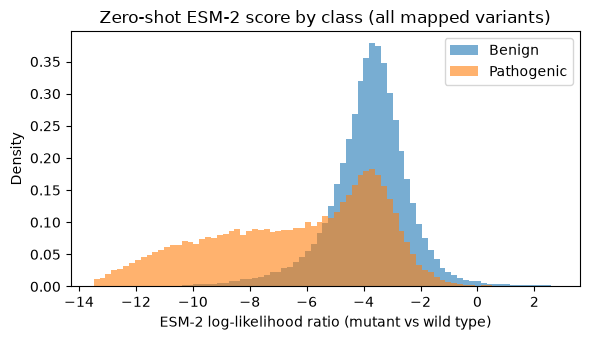

In [9]:
# How well does the zero-shot score separate the classes on its own?
esm_llr = pd.read_parquet(PROC / f"{TAG}.parquet", columns=["variation_id", "esm_llr"])
d = esm_llr.merge(feats[["variation_id", "label"]], on="variation_id")
fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.linspace(d["esm_llr"].quantile(0.001), d["esm_llr"].quantile(0.999), 80)
for lab, name in [(0, "Benign"), (1, "Pathogenic")]:
    ax.hist(d.loc[d["label"] == lab, "esm_llr"], bins=bins, density=True, alpha=0.6, label=name)
ax.set_xlabel("ESM-2 log-likelihood ratio (mutant vs wild type)")
ax.set_ylabel("Density")
ax.set_title("Zero-shot ESM-2 score by class (all mapped variants)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "esm_llr_by_class.png", dpi=150)
plt.show()

**`scripts/run_esm_models.py`** evaluates three Level 2 models on the mapped validation variants,
with the same splits, seeds and gene-grouped tuning as Level 1:
- **zero-shot**: `−esm_llr`, no training;
- **embedding + LR**: standardised embedding + `esm_llr`, L2 logistic regression,
  C ∈ {0.01, 0.1, 1} (the proposal's "small classifier on top");
- **trees + ESM score**: the Level 1 trees (swap + length + position) with `esm_llr` as a 19th feature.

In [10]:
show_md(f"{TAG}_summary.md")

# Level 2: ESM-2 (esm2_t12_35M_UR50D), mapped validation variants, 5 seeds

| Model | Split | AUROC | AUPRC | Brier | ECE | Per-gene AUROC |
|---|---|---|---|---|---|---|
| Level 1 trees (swap + position) | random | 0.834 ± 0.010 | 0.718 ± 0.018 | | | |
| Level 1 trees (swap + position) | gene | 0.781 ± 0.013 | 0.628 ± 0.019 | | | |
| ESM-2 zero-shot (no training) | random | 0.764 ± 0.005 | 0.692 ± 0.008 |  |  | 0.736 ± 0.012 |
| ESM-2 zero-shot (no training) | gene | 0.768 ± 0.011 | 0.696 ± 0.013 |  |  | 0.738 ± 0.021 |
| ESM-2 embedding + LR | random | 0.923 ± 0.003 | 0.863 ± 0.006 | 0.097 ± 0.002 | 0.005 ± 0.001 | 0.864 ± 0.011 |
| ESM-2 embedding + LR | gene | 0.918 ± 0.006 | 0.854 ± 0.009 | 0.102 ± 0.004 | 0.009 ± 0.002 | 0.851 ± 0.009 |
| Trees + ESM-2 score | random | 0.888 ± 0.008 | 0.822 ± 0.012 | 0.114 ± 0.004 | 0.017 ± 0.002 | 0.824 ± 0.013 |
| Trees + ESM-2 score | gene | 0.848 ± 0.016 | 0.775 ± 0.018 | 0.131 ± 0.006 | 0.017 ± 0.007 | 0.821 ± 0.013 |

Cost (mean over runs; ESM-2 inference itself is in reports/esm_esm2_t12_35M_UR50D_run.json):

- ESM-2 embedding + LR: training incl. tuning 7.3 s, inference 45.56 ms per 1,000, 14 KB
- Trees + ESM-2 score: training incl. tuning 13.2 s, inference 49.17 ms per 1,000, 444 KB


**Reading.** The embedding classifier reaches AUROC ≈ 0.92 on **unseen genes**, against 0.78 for
the best Level 1 model on the same variants, and its random and gene results are almost equal: it
is learning which positions are sensitive, not recognising genes. The zero-shot score alone (0.77)
is no better than the swap trees, so the gain comes from training on the embedding. Adding only
the zero-shot score to the trees helps (0.85) but keeps the random–gene gap of the length and
position features.

## 5. Interpretability of the Level 1 trees

The Phase 1 logistic regression has readable coefficients (BLOSUM62 strongest). Trees have no
coefficients, so we use **permutation importance**: how much validation AUROC drops when one
feature is shuffled (gene split, seed 0, saved model). The ESM-2 classifier has no equivalent:
its 481 weights act on learned embedding dimensions with no direct biological meaning.

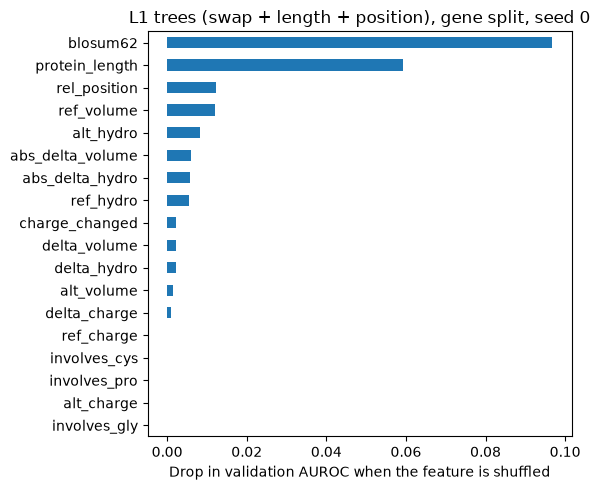

,AUROC drop
blosum62,0.0968
protein_length,0.0594
rel_position,0.0122
ref_volume,0.0120
alt_hydro,0.0082
abs_delta_volume,0.0059
abs_delta_hydro,0.0057
ref_hydro,0.0056
charge_changed,0.0022
delta_volume,0.0022


In [11]:
from sklearn.inspection import permutation_importance

splits = pd.read_parquet(ROOT / "data" / "splits" / "splits.parquet")
X_pos = pd.concat([feats[swap_cols], mapped[["protein_length", "rel_position"]]], axis=1)
val = (splits["gene_s0"] == "val").to_numpy()
gbm_pos = joblib.load(MODELS / "gbm_position_gene_s0.joblib")
imp = permutation_importance(gbm_pos, X_pos.to_numpy(dtype=float)[val], feats["label"].to_numpy()[val],
                             scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_pos.columns).sort_values()
fig, ax = plt.subplots(figsize=(6, 5))
imp.plot.barh(ax=ax)
ax.set_xlabel("Drop in validation AUROC when the feature is shuffled")
ax.set_title("L1 trees (swap + length + position), gene split, seed 0")
fig.tight_layout()
fig.savefig(FIGURES / "gbm_position_importance.png", dpi=150)
plt.show()
imp.sort_values(ascending=False).round(4).to_frame("AUROC drop")

## 6. Failure analysis and mitigations (validation part)

`scripts/failure_analysis.py` retrains the best Level 1 model (trees with length and position) and
the ESM-2 classifier on the gene split's training part, and measures them on the slices defined in
the proposal, on the **validation** part (every validation gene is unseen in training; 5 seeds).
The test part is not touched. Error rates use a 0.5 threshold.

**Mitigations.** (1) *Recalibration on separate genes*: validation genes are split in two halves;
isotonic or Platt scaling is fitted on one half and applied to the other, then swapped, so no gene
calibrates itself. (2) *Abstention*: the least confident 10/20/30% of variants are deferred to
expert review.

In [12]:
show_md("failure_summary.md")

# Failure analysis: gene split, mapped validation variants, 5 seeds (ESM-2 esm2_t12_35M_UR50D)

Numbers are means over the 5 seeds; n is variants per seed. Error rate uses a 0.5 threshold. AUROC is blank for one-class slices.

## Genes with few known variants

| Slice | n | % pathogenic | Trees: mean p | Trees: error | Trees: AUROC | ESM LR: mean p | ESM LR: error | ESM LR: AUROC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| <= 5 variants | 2,012 | 4.5% | 0.261 | 11.9% | 0.744 | 0.176 | 9.4% | 0.898 |
| 6-20 | 4,753 | 12.8% | 0.276 | 17.3% | 0.776 | 0.206 | 10.8% | 0.901 |
| 21-100 | 5,614 | 33.2% | 0.286 | 25.4% | 0.798 | 0.309 | 15.3% | 0.916 |
| > 100 | 5,758 | 52.7% | 0.315 | 32.6% | 0.835 | 0.440 | 18.3% | 0.924 |

## Benign variants in disease-heavy genes (false-positive rate)

| Slice | n | % pathogenic | Trees: mean p | Trees: error | Trees: AUROC | ESM LR: mean p | ESM LR: error | ESM LR: AUROC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| benign, disease-heavy genes | 835 | 0.0% | 0.254 | 11.2% |  | 0.219 | 13.7% |  |
| benign, other genes | 11,702 | 0.0% | 0.220 | 8.6% |  | 0.141 | 6.9% |  |

## Pathogenic variants with mild-looking swaps (false-negative rate)

| Slice | n | % pathogenic | Trees: mean p | Trees: error | Trees: AUROC | ESM LR: mean p | ESM LR: error | ESM LR: AUROC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| pathogenic, mild swap (BLOSUM62 >= 1) | 971 | 100.0% | 0.225 | 97.6% |  | 0.580 | 41.4% |  |
| pathogenic, harsh swap (BLOSUM62 <= 0) | 4,629 | 100.0% | 0.485 | 50.1% |  | 0.693 | 27.9% |  |

## Recently classified variants

| Slice | n | % pathogenic | Trees: mean p | Trees: error | Trees: AUROC | ESM LR: mean p | ESM LR: error | ESM LR: AUROC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| evaluated 2025-2026 | 8,539 | 28.3% | 0.283 | 23.2% | 0.770 | 0.300 | 13.7% | 0.920 |
| evaluated before 2025 | 9,420 | 32.3% | 0.293 | 24.3% | 0.788 | 0.311 | 14.8% | 0.918 |
| date missing | 177 | 83.9% | 0.420 | 50.4% | 0.680 | 0.609 | 26.4% | 0.851 |

## Label confidence (ClinVar review stars)

| Slice | n | % pathogenic | Trees: mean p | Trees: error | Trees: AUROC | ESM LR: mean p | ESM LR: error | ESM LR: AUROC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| 1 star | 12,025 | 26.6% | 0.283 | 20.9% | 0.796 | 0.282 | 13.1% | 0.921 |
| 2+ stars | 6,112 | 39.3% | 0.302 | 30.3% | 0.756 | 0.362 | 17.1% | 0.911 |

## Low-confidence predictions (bins are per model)

| Slice | n | % pathogenic | Trees: mean p | Trees: error | Trees: AUROC | ESM LR: mean p | ESM LR: error | ESM LR: AUROC |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| |p - 0.5| in [0.0, 0.1) | 2,690 / 1,547 | 52.1% | 0.495 | 45.5% | 0.568 | 0.494 | 45.7% | 0.558 |
| |p - 0.5| in [0.1, 0.2) | 3,106 / 1,705 | 46.9% | 0.451 | 34.8% | 0.667 | 0.464 | 35.4% | 0.652 |
| |p - 0.5| in [0.2, 0.3) | 4,022 / 2,003 | 36.2% | 0.348 | 25.0% | 0.708 | 0.402 | 26.6% | 0.729 |
| |p - 0.5| in [0.3, 0.4) | 4,853 / 2,981 | 20.9% | 0.189 | 16.2% | 0.646 | 0.321 | 14.3% | 0.835 |
| |p - 0.5| in [0.4, 0.5] | 3,465 / 9,900 | 7.8% | 0.058 | 7.7% | 0.695 | 0.231 | 3.5% | 0.967 |

## Mitigation 1: recalibration on separate validation genes

Isotonic / Platt fitted on half of the validation genes, applied to the other half, then swapped.

| Model | Method | Brier | ECE | AUROC |
|---|---|---|---|---|
| Level 1 trees | none | 0.166 ± 0.002 | 0.022 ± 0.007 | 0.780 |
| Level 1 trees | isotonic | 0.171 ± 0.006 | 0.031 ± 0.016 | 0.764 |
| Level 1 trees | platt | 0.170 ± 0.005 | 0.018 ± 0.008 | 0.768 |
| ESM-2 embedding + LR | none | 0.102 ± 0.004 | 0.009 ± 0.002 | 0.918 |
| ESM-2 embedding + LR | isotonic | 0.105 ± 0.006 | 0.013 ± 0.009 | 0.914 |
| ESM-2 embedding + LR | platt | 0.104 ± 0.006 | 0.009 ± 0.003 | 0.915 |

## Mitigation 2: abstain on the least confident variants

| Model | Deferred to expert review | Error rate on kept | Errors removed | AUROC on kept |
|---|---|---:|---:|---:|
| Level 1 trees | 0% | 24.1% | 0.0% | 0.780 |
| Level 1 trees | 10% | 21.4% | 19.8% | 0.780 |
| Level 1 trees | 20% | 19.1% | 36.4% | 0.772 |
| Level 1 trees | 30% | 17.0% | 50.5% | 0.760 |
| ESM-2 embedding + LR | 0% | 14.4% | 0.0% | 0.918 |
| ESM-2 embedding + LR | 10% | 11.0% | 31.1% | 0.931 |
| ESM-2 embedding + LR | 20% | 8.2% | 54.7% | 0.943 |
| ESM-2 embedding + LR | 30% | 5.8% | 72.0% | 0.953 |

- Unmapped variants (7.2%) have no ESM-2 score; in deployment they would fall back to the Level 1 trees or be deferred.


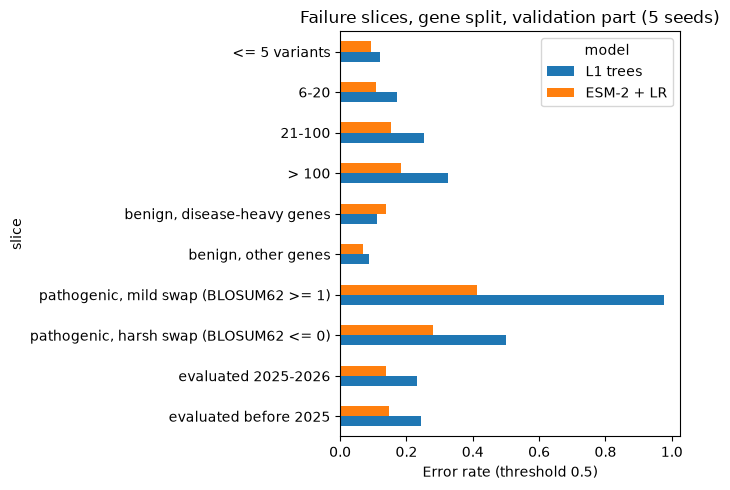

In [13]:
sl = pd.read_csv(REPORTS / "failure_slices.csv")
show = ["<= 5 variants", "6-20", "21-100", "> 100",
        "benign, disease-heavy genes", "benign, other genes",
        "pathogenic, mild swap (BLOSUM62 >= 1)", "pathogenic, harsh swap (BLOSUM62 <= 0)",
        "evaluated 2025-2026", "evaluated before 2025"]
err = sl[sl["slice"].isin(show)].groupby(["slice", "model"])["error_rate"].mean().unstack()
err = err.loc[show, ["trees", "emb_lr"]].rename(columns={"trees": "L1 trees", "emb_lr": "ESM-2 + LR"})
fig, ax = plt.subplots(figsize=(7, 5))
err[::-1].plot.barh(ax=ax)
ax.set_xlabel("Error rate (threshold 0.5)")
ax.set_title("Failure slices, gene split, validation part (5 seeds)")
fig.tight_layout()
fig.savefig(FIGURES / "failure_slices.png", dpi=150)
plt.show()

**Reading.**
- *Genes with few variants*: the ESM-2 classifier keeps AUROC ≈ 0.90 even for genes with at most
  five known variants; the trees drop to ≈ 0.74.
- *Benign variants in disease-heavy genes* are the ESM-2 model's clearest weakness: its
  false-positive rate roughly doubles. Pathogenic variants cluster in critical regions of these
  proteins, so the model partly learns "this region is dangerous" rather than "this swap is
  dangerous".
- *Pathogenic variants with mild-looking swaps*: swap features miss almost all of them; ESM-2
  catches more than half but this remains its largest error group.
- *Recently classified variants*: no degradation.
- *Low confidence*: errors concentrate where |p − 0.5| is small.
- *Recalibration* does not help: the ESM-2 classifier is already well calibrated on unseen genes,
  and isotonic scaling on half the genes adds noise. A valid negative result.
- *Abstention* works: deferring the least confident 20% removes more than half of the errors.

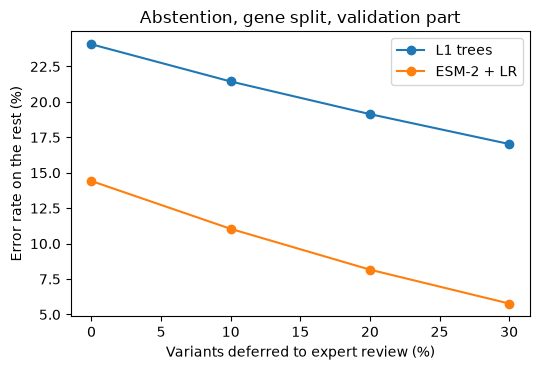

In [14]:
mit = pd.read_csv(REPORTS / "failure_mitigation.csv")
ab = mit[mit["kind"] == "abstention"].groupby(["model", "deferred"])[["error_rate_kept"]].mean().reset_index()
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for name, label in [("trees", "L1 trees"), ("emb_lr", "ESM-2 + LR")]:
    a = ab[ab["model"] == name]
    ax.plot(a["deferred"] * 100, a["error_rate_kept"] * 100, "o-", label=label)
ax.set_xlabel("Variants deferred to expert review (%)")
ax.set_ylabel("Error rate on the rest (%)")
ax.set_title("Abstention, gene split, validation part")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "abstention.png", dpi=150)
plt.show()

## 7. Final evaluation on the test part (used once)

`scripts/final_test.py` is the only script that reads the test part. The protocol was fixed before
running it: every model is re-tuned and refit on train + validation (same grids, gene-grouped
5-fold CV), then scored once on test, for both splits and all 5 seeds. The main comparison is on
mapped test variants, which every model can score; Level 1 models are also scored on all test
variants. 95% confidence intervals come from 1,000 bootstrap resamples of test **genes** (seed 0),
which respects the correlation of variants within a gene.

*Note.* In 3 of the 10 ESM-2 LR refits, a few cross-validation fits ran out of memory (too many
parallel copies of the embedding matrix), so C was chosen among fewer candidates. The tuning curve
is flat (AUPRC 0.8477 vs 0.8476) and every final refit succeeded; we did not re-run, to avoid a
second look at the test part.

In [15]:
show_md("final_test_summary.md")

# Final test results (ESM-2 esm2_t12_35M_UR50D)

Each model refit on train + val, scored once on the TEST part; mean ± std over 5 seeds, mapped test variants. 'AUROC, all' includes unmapped variants (Level 1 models only).

| Model | Split | AUROC | AUPRC | Brier | ECE | Per-gene AUROC | AUROC, all |
|---|---|---|---|---|---|---|---|
| Gene-only reference (diagnostic) | random | 0.932 ± 0.002 | 0.869 ± 0.005 | 0.091 ± 0.002 | 0.019 ± 0.002 | 0.500 ± 0.000 |  |
| Gene-only reference (diagnostic) | gene | 0.500 ± 0.000 | 0.301 ± 0.002 | 0.210 ± 0.001 | 0.005 ± 0.002 | 0.500 ± 0.000 |  |
| L1 logistic regression (swap) | random | 0.731 ± 0.002 | 0.541 ± 0.004 | 0.181 ± 0.001 | 0.019 ± 0.002 | 0.716 ± 0.008 | 0.731 ± 0.002 |
| L1 logistic regression (swap) | gene | 0.720 ± 0.005 | 0.516 ± 0.008 | 0.183 ± 0.002 | 0.022 ± 0.001 | 0.715 ± 0.010 | 0.720 ± 0.006 |
| L1 trees (swap) | random | 0.763 ± 0.002 | 0.592 ± 0.003 | 0.171 ± 0.001 | 0.008 ± 0.001 | 0.735 ± 0.009 | 0.762 ± 0.002 |
| L1 trees (swap) | gene | 0.754 ± 0.006 | 0.567 ± 0.006 | 0.173 ± 0.002 | 0.011 ± 0.001 | 0.734 ± 0.010 | 0.754 ± 0.005 |
| L1 trees (swap + length + position) | random | 0.830 ± 0.009 | 0.711 ± 0.018 | 0.147 ± 0.005 | 0.022 ± 0.004 | 0.755 ± 0.009 | 0.828 ± 0.009 |
| L1 trees (swap + length + position) | gene | 0.775 ± 0.012 | 0.612 ± 0.015 | 0.166 ± 0.004 | 0.016 ± 0.003 | 0.748 ± 0.009 | 0.773 ± 0.011 |
| L2 ESM-2 zero-shot | random | 0.763 ± 0.002 | 0.692 ± 0.003 |  |  | 0.736 ± 0.007 |  |
| L2 ESM-2 zero-shot | gene | 0.752 ± 0.011 | 0.673 ± 0.017 |  |  | 0.716 ± 0.008 |  |
| L2 ESM-2 embedding + LR | random | 0.923 ± 0.001 | 0.864 ± 0.002 | 0.097 ± 0.000 | 0.004 ± 0.001 | 0.856 ± 0.006 |  |
| L2 ESM-2 embedding + LR | gene | 0.924 ± 0.003 | 0.861 ± 0.006 | 0.097 ± 0.003 | 0.006 ± 0.002 | 0.848 ± 0.011 |  |
| L2 trees + ESM-2 score | random | 0.892 ± 0.001 | 0.827 ± 0.003 | 0.113 ± 0.001 | 0.017 ± 0.002 | 0.826 ± 0.004 |  |
| L2 trees + ESM-2 score | gene | 0.841 ± 0.011 | 0.758 ± 0.016 | 0.134 ± 0.005 | 0.017 ± 0.006 | 0.812 ± 0.010 |  |

## Gene-level bootstrap 95% CIs (seed 0, 1,000 resamples of test genes)

| Model | Split | AUROC [95% CI] | AUPRC [95% CI] |
|---|---|---|---|
| Gene-only reference (diagnostic) | random | 0.932 [0.925, 0.938] | 0.868 [0.848, 0.884] |
| L1 logistic regression (swap) | random | 0.729 [0.717, 0.744] | 0.541 [0.502, 0.584] |
| L1 trees (swap) | random | 0.761 [0.748, 0.775] | 0.594 [0.553, 0.637] |
| L1 trees (swap + length + position) | random | 0.829 [0.814, 0.842] | 0.711 [0.668, 0.752] |
| L2 ESM-2 zero-shot | random | 0.764 [0.747, 0.782] | 0.693 [0.655, 0.730] |
| L2 ESM-2 embedding + LR | random | 0.923 [0.916, 0.929] | 0.864 [0.844, 0.882] |
| L2 trees + ESM-2 score | random | 0.892 [0.882, 0.902] | 0.829 [0.803, 0.854] |
| AUROC difference: ESM-2 LR minus L1 trees (swap + position) | random | +0.094 [+0.083, +0.106] |  |
| Gene-only reference (diagnostic) | gene | 0.500 [0.500, 0.500] | 0.302 [0.249, 0.352] |
| L1 logistic regression (swap) | gene | 0.719 [0.703, 0.736] | 0.515 [0.445, 0.576] |
| L1 trees (swap) | gene | 0.754 [0.738, 0.770] | 0.568 [0.494, 0.628] |
| L1 trees (swap + length + position) | gene | 0.790 [0.758, 0.821] | 0.634 [0.524, 0.720] |
| L2 ESM-2 zero-shot | gene | 0.744 [0.716, 0.774] | 0.657 [0.585, 0.721] |
| L2 ESM-2 embedding + LR | gene | 0.923 [0.909, 0.935] | 0.858 [0.811, 0.895] |
| L2 trees + ESM-2 score | gene | 0.853 [0.827, 0.875] | 0.771 [0.702, 0.823] |
| AUROC difference: ESM-2 LR minus L1 trees (swap + position) | gene | +0.132 [+0.106, +0.160] |  |

## Drop from random to gene split (sub-question 1)

| Model | AUROC random - gene |
|---|---:|
| Gene-only reference (diagnostic) | +0.432 |
| L1 logistic regression (swap) | +0.012 |
| L1 trees (swap) | +0.009 |
| L1 trees (swap + length + position) | +0.055 |
| L2 ESM-2 zero-shot | +0.011 |
| L2 ESM-2 embedding + LR | -0.000 |
| L2 trees + ESM-2 score | +0.050 |

## Complexity (sub-question 2: what the improvement costs)

Mean over the 10 refits on train + val. Training includes the hyperparameter search. Inference is the classifier only; the ESM-2 feature cost is listed separately (one GPU pass over every protein).

| Model | Features | Learned numbers | Size (KB) | Training incl. tuning (s, CPU) | Inference (ms / 1,000, CPU) | Feature cost (ms / 1,000) | Test AUROC, gene split |
|---|---|---:|---:|---:|---:|---:|---:|
| L1 logistic regression (swap) | 16 swap | 17 | 2 | 1.8 | 0.15 | ≈ 0 | 0.720 |
| L1 trees (swap) | 16 swap | 10,280 | 595 | 17.1 | 4.92 | ≈ 0 | 0.754 |
| L1 trees (swap + length + position) | 18 | 5,480 | 337 | 16.4 | 3.76 | ≈ 0 | 0.775 |
| L2 ESM-2 zero-shot | 1 (ESM-2 LLR) | 0 (pretrained only) | | 0 | 0 | 1,137 on NVIDIA GeForce RTX 5070 Ti Laptop GPU | 0.752 |
| L2 ESM-2 embedding + LR | 481 (ESM-2) | 482 | 14 | 8.0 | 2.07 | 1,137 on NVIDIA GeForce RTX 5070 Ti Laptop GPU | 0.924 |
| L2 trees + ESM-2 score | 19 (incl. ESM-2 LLR) | 12,200 | 707 | 17.2 | 5.13 | 1,137 on NVIDIA GeForce RTX 5070 Ti Laptop GPU | 0.841 |

ESM-2 pass over all 14,743 proteins: 210 s on NVIDIA GeForce RTX 5070 Ti Laptop GPU (18,282 windows of up to 1,022 residues). ESM-2 esm2_t12_35M_UR50D itself is a pretrained network of about 35 M parameters (not trained here).

## Abstention on the test part (ESM-2 embedding + LR)

| Split | Deferred | Error rate on kept | Errors removed | AUROC on kept |
|---|---:|---:|---:|---:|
| gene | 0% | 13.5% | 0.0% | 0.924 |
| gene | 10% | 10.2% | 32.5% | 0.936 |
| gene | 20% | 7.3% | 56.8% | 0.946 |
| gene | 30% | 5.3% | 72.8% | 0.955 |
| random | 0% | 13.6% | 0.0% | 0.923 |
| random | 10% | 10.2% | 32.5% | 0.935 |
| random | 20% | 7.4% | 56.3% | 0.945 |
| random | 30% | 5.3% | 72.8% | 0.955 |


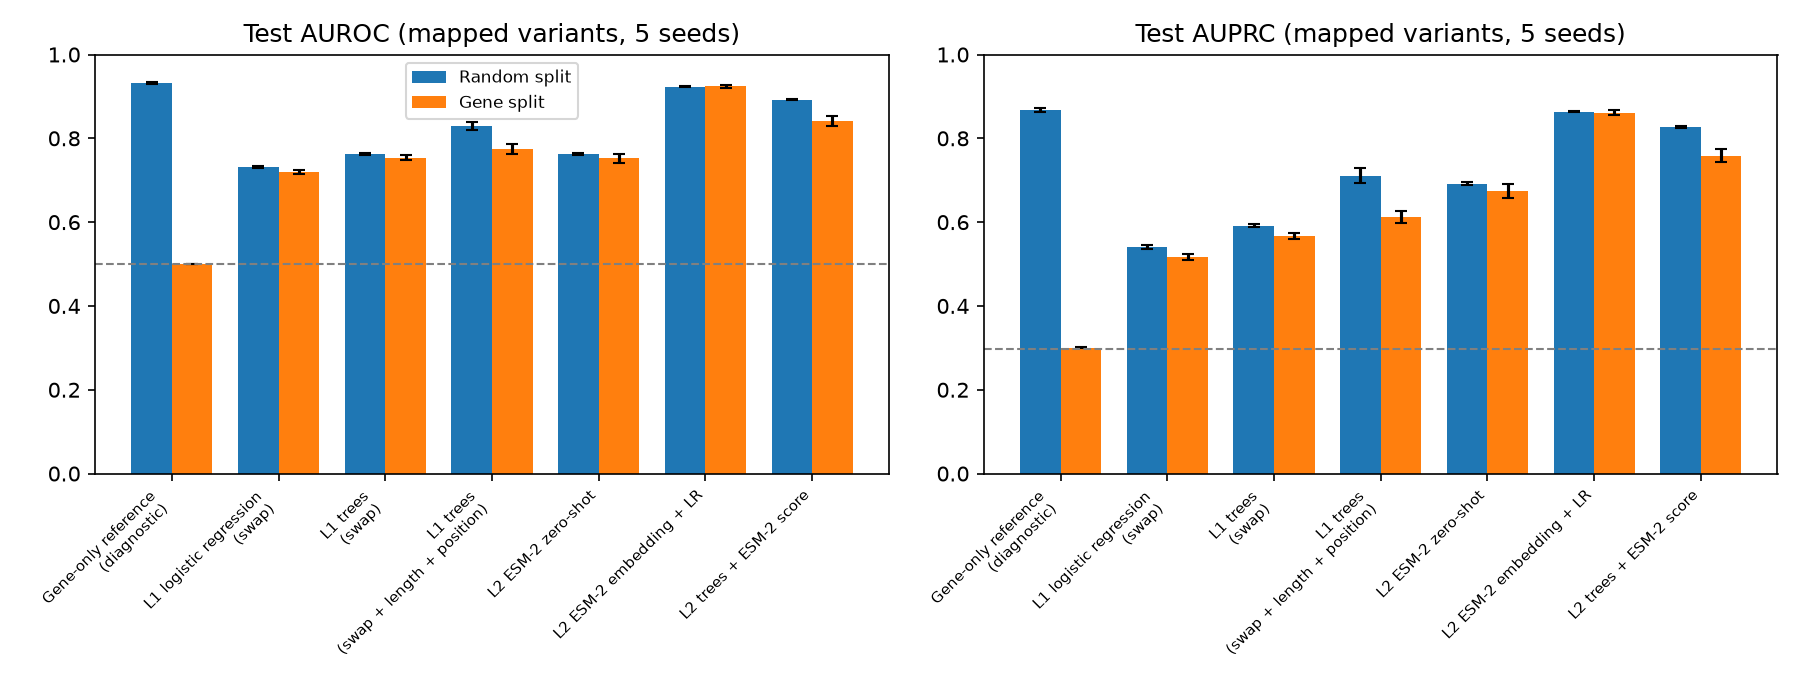

In [16]:
display(Image(str(FIGURES / "final_test_metrics.png")))

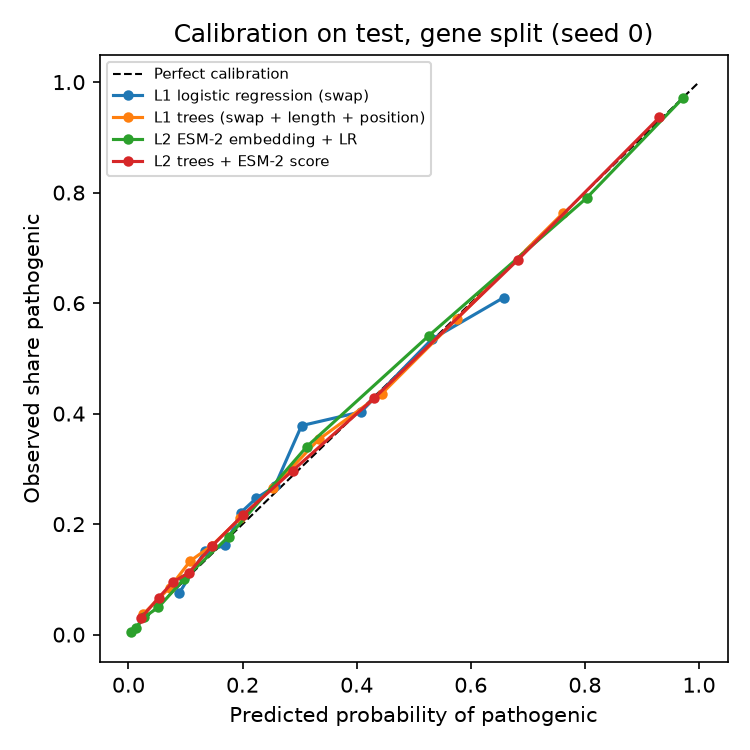

In [17]:
display(Image(str(FIGURES / "final_test_calibration.png")))

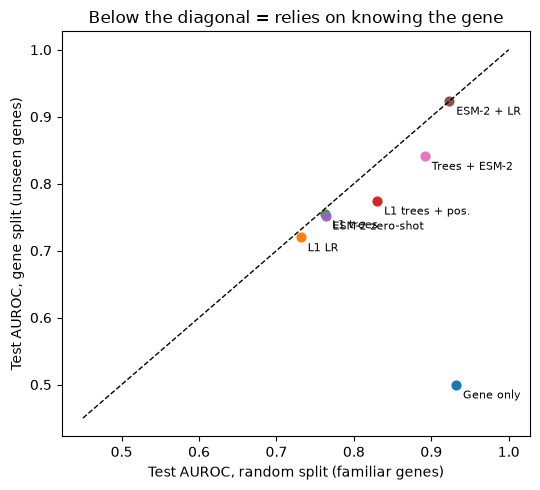

In [18]:
# Sub-question 1 in one picture: AUROC on familiar (random split) vs unseen (gene split) genes.
res = pd.read_csv(REPORTS / "final_test_results.csv")
order = ["gene_prior", "logreg", "gbm", "gbm_position", "zero_shot", "emb_lr", "gbm_esm"]
names = {"gene_prior": "Gene only", "logreg": "L1 LR", "gbm": "L1 trees",
         "gbm_position": "L1 trees + pos.", "zero_shot": "ESM-2 zero-shot",
         "emb_lr": "ESM-2 + LR", "gbm_esm": "Trees + ESM-2"}
m = res.groupby(["model", "split"])["auroc"].mean().unstack().loc[order]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0.45, 1], [0.45, 1], "k--", lw=1)
for k, r in m.iterrows():
    ax.scatter(r["random"], r["gene"], s=40)
    ax.annotate(names[k], (r["random"], r["gene"]), textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.set_xlabel("Test AUROC, random split (familiar genes)")
ax.set_ylabel("Test AUROC, gene split (unseen genes)")
ax.set_title("Below the diagonal = relies on knowing the gene")
fig.tight_layout()
fig.savefig(FIGURES / "final_random_vs_gene.png", dpi=150)
plt.show()

## 8. Complexity analysis

The complexity table is in the test summary above (section "Complexity"). In short:
- **Level 1** runs on any CPU: the logistic regression is 17 numbers and 2 KB; the trees take
  about 17 s to tune and 300–700 KB.
- **Level 2** needs the ESM-2 features first: one pass of a 35M-parameter network over every
  protein, 210 s on an RTX 5070 Ti laptop GPU (about 1.1 s per 1,000 variants, roughly 500× the
  cost of the classifier itself). After that, the classifier is 482 numbers and 14 KB.
- **Interpretability**: Level 1 coefficients and permutation importances (section 5) are
  readable; the ESM-2 classifier's weights are not.

**Verdict.** For +0.13 AUROC on unseen genes at the cost of a few GPU minutes, Level 2 is worth it
under both splits. Its zero-shot score alone would not be.

## 9. Using the released model

The final model, `models/final_esm_lr.joblib`, is the ESM-2 embedding + logistic regression trained
on train + validation of gene split seed 0. `models/final_esm_lr.json` documents its inputs. To
score new variants: compute the ESM-2 features with `scripts/esm_scores.py`, then call
`predict_proba` on the columns in `feature_order`. Here we reload it and score a few test variants.

In [19]:
final = joblib.load(MODELS / "final_esm_lr.joblib")
info = json.loads((MODELS / "final_esm_lr.json").read_text())
print(info["what"], "|", info["esm_model"], "|", len(info["feature_order"]), "inputs")

emb = pd.read_parquet(PROC / f"{TAG}.parquet")
test_ids = feats.loc[(splits["gene_s0"] == "test").to_numpy(), "variation_id"]
sample = emb[emb["variation_id"].isin(test_ids)].sample(8, random_state=0)
p = final.predict_proba(sample[info["feature_order"]].to_numpy(dtype=np.float32))[:, 1]
v = pd.read_parquet(PROC / "variants.parquet", columns=["variation_id", "gene", "ref_aa", "protein_pos",
                                                       "alt_aa", "clinical_significance"])
out = sample[["variation_id"]].assign(p_pathogenic=p.round(3)).merge(v, on="variation_id")
out

ESM-2 embedding + L2 logistic regression (StandardScaler + LogisticRegression) | facebook/esm2_t12_35M_UR50D | 481 inputs


,variation_id,p_pathogenic,gene,ref_aa,protein_pos,alt_aa,clinical_significance
0,2170343,0.022,KMT2D,Glu,4733,Lys,Benign/Likely benign
1,1560282,0.010,SETBP1,Glu,324,Gln,Likely benign
2,2712323,0.001,TRIM28,Thr,567,Ala,Benign/Likely benign
3,4169739,0.000,SLFNL1,Lys,147,Glu,Likely benign
4,2545766,0.012,IGSF1,Arg,1111,Ser,Likely benign
5,1493803,0.013,SETBP1,Val,924,Met,Benign
6,2281929,0.015,FCGR2C,Val,149,Met,Likely benign
7,2054917,0.456,TRPV4,Ser,542,Pro,Likely pathogenic


## 10. Conclusions

1. **Unseen genes (sub-question 1).** A random split overstates what a model has learned: the
   gene name alone gives AUROC 0.93 there and 0.50 on unseen genes. Features that identify genes
   (protein length) inflate random-split results; the ESM-2 classifier shows no drop at all.
2. **What the language model adds (sub-question 2).** On unseen genes, ESM-2 embedding + LR reaches
   test AUROC 0.924 (mean of 5 seeds; seed 0: 0.923 [0.909, 0.935]), +0.132 [+0.106, +0.160] (seed 0) over the best classical model, for one
   GPU pass over the proteome and a loss of direct interpretability.
3. **Trusting the confidence (sub-question 3).** The ESM-2 classifier is well calibrated on unseen
   genes (test ECE 0.006) and recalibration is unnecessary; deferring the 20% least confident
   variants removes more than half of the errors.
4. **Remaining failures.** Benign variants in disease-heavy genes, and pathogenic variants with
   mild-looking swaps.

**Not done from the proposal** (time): phyloP conservation, the gnomAD allele-frequency ablation,
mutant-sequence embeddings, and larger ESM-2 models. These are the natural next steps, together
with a split by gene family to rule out paralog leakage.

## Appendix: complete source code of the Phase 2 scripts

Every step in this notebook is computed by the scripts below, run in this order (with `RUN_PIPELINE = True` in section 1, or from the command line as described in the README); the cells above read and explain their outputs. Their complete source is reproduced here so that all the code we used is in this notebook, from the UniProt download and sequence mapping to the ESM-2 features, training, hyperparameter tuning, model selection, failure analysis and the final test. The Phase 1 scripts are in the appendix of notebook 01. The same files are in `scripts/` in the repository.

### A.1 `scripts/run_gbm.py`

````python
"""Strong Level-1 baseline: gradient-boosted trees on the swap features (proposal section 5).

Run from the repo root:  python scripts/run_gbm.py
Inputs:  data/processed/features_swap.parquet, data/splits/splits.parquet
Outputs: reports/gbm_results.csv          one row per (model, split type, seed)
         reports/gbm_summary.md           mean +/- std over seeds, chosen settings, cost
         models/gbm_<split>_s0.joblib     trained models (seed 0)

Models
  gbm          : scikit-learn HistGradientBoostingClassifier on the same 16 swap features as the
                 logistic regression. Hyperparameters tuned by 5-fold gene-grouped CV inside the
                 training part only, scored by AUPRC (same protocol as run_baseline.py).
  swap_lookup  : diagnostic, not a model. Predicts each variant by the share of pathogenic
                 variants with the SAME amino-acid swap (e.g. Arg>Cys) in training. The 16 swap
                 features take only 150 distinct values (one per swap type), so every model that
                 sees only these features is a function of the swap type; this lookup is the best
                 such function the training data supports, i.e. the ceiling for swap-only models.

Evaluation is on the VAL part; the TEST part is not touched. No class weighting (see
run_baseline.py).
"""
import pickle
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold

ROOT = Path(__file__).resolve().parents[1]
FEATURES = ROOT / "data" / "processed" / "features_swap.parquet"
SPLITS = ROOT / "data" / "splits" / "splits.parquet"
REPORTS = ROOT / "reports"
MODELS = ROOT / "models"

SEEDS = [0, 1, 2, 3, 4]
SPLIT_TYPES = ["random", "gene"]
GRID = {"learning_rate": [0.05, 0.1],
        "max_leaf_nodes": [7, 31],
        "min_samples_leaf": [20, 200]}
METRICS = ["auroc", "auprc", "brier", "ece", "per_gene_auroc"]


def per_gene_auroc(genes, y, p):
    """Mean AUROC computed separately inside each gene that has both classes."""
    df = pd.DataFrame({"g": genes, "y": y, "p": p})
    scores = [roc_auc_score(d["y"], d["p"]) for _, d in df.groupby("g") if d["y"].nunique() == 2]
    return (float(np.mean(scores)) if scores else np.nan), len(scores)


def ece(y, p, n_bins=10):
    """Expected calibration error, 10 bins with equal numbers of variants (as in the notebook)."""
    bins = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))


def evaluate(genes, y, p):
    pga, n_genes = per_gene_auroc(genes, y, p)
    return {"auroc": roc_auc_score(y, p), "auprc": average_precision_score(y, p),
            "brier": brier_score_loss(y, p), "ece": ece(y, p), "per_gene_auroc": pga,
            "genes_in_per_gene_auroc": n_genes, "p_min": float(p.min()), "p_max": float(p.max())}


def fit_gbm(X, y, groups, seed):
    """Tune by gene-grouped CV inside the training data; return best model, params, seconds."""
    model = HistGradientBoostingClassifier(max_iter=200, early_stopping=False, random_state=seed)
    search = GridSearchCV(model, GRID, scoring="average_precision",
                          cv=GroupKFold(n_splits=5), n_jobs=-1)
    t0 = time.perf_counter()
    search.fit(X, y, groups=groups)
    return search.best_estimator_, search.best_params_, time.perf_counter() - t0


def swap_lookup(train_swaps, train_y, query_swaps):
    """Share of pathogenic variants per swap type in training; unseen swaps get the overall share."""
    rate = pd.Series(train_y).groupby(train_swaps).mean()
    return pd.Series(query_swaps).map(rate).fillna(train_y.mean()).to_numpy()


def main():
    feats = pd.read_parquet(FEATURES)
    splits = pd.read_parquet(SPLITS)
    if not (feats["variation_id"].to_numpy() == splits["variation_id"].to_numpy()).all():
        raise RuntimeError("Features and splits are not in the same order: rerun "
                           "build_features.py, then make_splits.py.")
    feature_cols = [c for c in feats.columns if c not in ("variation_id", "gene", "label")]
    X, y, genes = feats[feature_cols].to_numpy(), feats["label"].to_numpy(), feats["gene"].to_numpy()
    # One id per swap type: identical feature vectors <=> identical swap.
    swaps = pd.Series([tuple(r) for r in X]).astype("category").cat.codes.to_numpy()
    print(f"{len(np.unique(swaps))} distinct swap types among {len(X):,} variants")

    MODELS.mkdir(parents=True, exist_ok=True)
    rows = []
    for split_type in SPLIT_TYPES:
        for seed in SEEDS:
            part = splits[f"{split_type}_s{seed}"].to_numpy()
            tr, va = part == "train", part == "val"

            model, params, train_s = fit_gbm(X[tr], y[tr], genes[tr], seed)
            t0 = time.perf_counter()
            p = model.predict_proba(X[va])[:, 1]
            infer_ms = (time.perf_counter() - t0) / va.sum() * 1000 * 1000  # per 1,000 variants
            rows.append({"model": "gbm", "split": split_type, "seed": seed,
                         **evaluate(genes[va], y[va], p), **params,
                         "train_seconds": train_s, "infer_ms_per_1000": infer_ms,
                         "size_kb": len(pickle.dumps(model)) / 1024})
            if seed == 0:
                joblib.dump(model, MODELS / f"gbm_{split_type}_s0.joblib")

            p_lookup = swap_lookup(swaps[tr], y[tr], swaps[va])
            rows.append({"model": "swap_lookup", "split": split_type, "seed": seed,
                         **evaluate(genes[va], y[va], p_lookup)})
            print(f"{split_type:<6} seed {seed}: gbm AUROC {rows[-2]['auroc']:.3f} "
                  f"AUPRC {rows[-2]['auprc']:.3f} | swap_lookup AUROC {rows[-1]['auroc']:.3f} "
                  f"AUPRC {rows[-1]['auprc']:.3f}  ({params}, {train_s:.1f}s)")

    res = pd.DataFrame(rows)
    res.to_csv(REPORTS / "gbm_results.csv", index=False)

    # Summary, with the logistic regression from run_baseline.py alongside for comparison.
    both = res
    lr_path = REPORTS / "baseline_results.csv"
    if lr_path.exists():
        lr = pd.read_csv(lr_path)
        lr = lr[lr["model"] == "logreg"]
        both = pd.concat([lr, res], ignore_index=True)
    shown = [m for m in METRICS if m in both.columns]
    agg = both.groupby(["model", "split"])[shown].agg(["mean", "std"])
    lines = ["# Gradient-boosted trees on the swap features (validation part, 5 seeds)", "",
             "| Model | Split | " + " | ".join(m.upper().replace("_", " ") for m in shown) + " |",
             "|---|---|" + "---|" * len(shown)]
    for model_name in ["logreg", "gbm", "swap_lookup"]:
        for split_type in SPLIT_TYPES:
            if (model_name, split_type) not in agg.index:
                continue
            r = agg.loc[(model_name, split_type)]
            cells = ["-" if pd.isna(r[(m, "mean")])
                     else f"{r[(m, 'mean')]:.3f} ± {r[(m, 'std')]:.3f}" for m in shown]
            lines.append(f"| {model_name} | {split_type} | " + " | ".join(cells) + " |")
    g = res[res["model"] == "gbm"]
    chosen = g[list(GRID)].astype(str).agg(", ".join, axis=1).value_counts()
    lines += ["", "ECE for logreg was computed only for seed 0 in the notebook (0.018).", "",
              "## Gradient-boosted trees: settings and cost", "",
              f"- Grid: {GRID}, max_iter=200, tuned by 5-fold GroupKFold on train, scored by AUPRC",
              "- Chosen (learning_rate, max_leaf_nodes, min_samples_leaf) across the 10 runs: "
              + "; ".join(f"{k} x{v}" for k, v in chosen.items()),
              f"- Training time incl. tuning: {g['train_seconds'].mean():.1f} s on average "
              "(wall-clock, parallel; depends on the machine)",
              f"- Inference: {g['infer_ms_per_1000'].mean():.3f} ms per 1,000 variants",
              f"- Model size: {g['size_kb'].mean():.0f} KB",
              f"- Predicted probabilities range {g['p_min'].min():.2f} to {g['p_max'].max():.2f}",
              "", "swap_lookup is a diagnostic: the best any swap-only model can do on this data."]
    (REPORTS / "gbm_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n" + "\n".join(lines))


if __name__ == "__main__":
    main()
````

### A.2 `scripts/fetch_uniprot.py`

````python
"""Download the reviewed (Swiss-Prot) human proteome from UniProt, once, and record it.

Run from the repo root:  python scripts/fetch_uniprot.py
Outputs: data/processed/uniprot_human.tsv   one row per protein: accession, gene, length, sequence
         reports/uniprot_snapshot.json      release, download date, row count, MD5

UniProt is updated every 8 weeks, so the release number is recorded, like the ClinVar snapshot.
If the TSV already exists, the script only checks it and does not download again.
"""
import datetime
import hashlib
import json
from pathlib import Path

import pandas as pd
import requests

ROOT = Path(__file__).resolve().parents[1]
OUT = ROOT / "data" / "processed" / "uniprot_human.tsv"
RECORD = ROOT / "reports" / "uniprot_snapshot.json"
URL = ("https://rest.uniprot.org/uniprotkb/stream"
       "?query=(reviewed:true)%20AND%20(organism_id:9606)"
       "&format=tsv&fields=accession,gene_primary,length,sequence")


def main():
    if not OUT.exists():
        print("Downloading reviewed human proteins from UniProt (about 15 MB)...")
        r = requests.get(URL, timeout=300)
        r.raise_for_status()
        OUT.parent.mkdir(parents=True, exist_ok=True)
        OUT.write_bytes(r.content)
        record = {"source_url": URL,
                  "uniprot_release": r.headers.get("X-UniProt-Release", "unknown"),
                  "downloaded_at": datetime.datetime.now().isoformat(timespec="seconds"),
                  "md5": hashlib.md5(r.content).hexdigest()}
    else:
        print(f"Found {OUT}; not downloading again.")
        record = json.loads(RECORD.read_text()) if RECORD.exists() else {}

    df = pd.read_csv(OUT, sep="\t")
    df.columns = ["accession", "gene", "length", "sequence"]
    record["rows"] = len(df)
    record["rows_with_gene_name"] = int(df["gene"].notna().sum())
    record["genes_with_more_than_one_entry"] = int(df["gene"].dropna().duplicated().sum())
    RECORD.write_text(json.dumps(record, indent=2))
    print(json.dumps(record, indent=2))
    print(f"\nSaved {OUT}\nSaved {RECORD}")


if __name__ == "__main__":
    main()
````

### A.3 `scripts/map_sequences.py`

````python
"""Map every variant to its UniProt protein and add protein length and relative position.

Run from the repo root:  python scripts/map_sequences.py
Inputs:  data/processed/variants.parquet, data/processed/uniprot_human.tsv (fetch_uniprot.py)
Outputs: data/processed/variants_mapped.parquet   same rows and order as variants.parquet
         reports/mapping_summary.md               how many variants map, and why the rest don't

A variant is "mapped" when its gene is in UniProt AND the UniProt sequence has ClinVar's
original amino acid at ClinVar's position. ClinVar positions come from a RefSeq transcript,
which is not always the same isoform as UniProt's canonical sequence; the residue check
catches those cases instead of silently attaching the wrong position.
Protein length and relative position are only filled in for mapped variants.
"""
import time
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parents[1]
VARIANTS = ROOT / "data" / "processed" / "variants.parquet"
UNIPROT = ROOT / "data" / "processed" / "uniprot_human.tsv"
OUT = ROOT / "data" / "processed" / "variants_mapped.parquet"
SUMMARY = ROOT / "reports" / "mapping_summary.md"

THREE_TO_ONE = {"Ala": "A", "Arg": "R", "Asn": "N", "Asp": "D", "Cys": "C", "Gln": "Q",
                "Glu": "E", "Gly": "G", "His": "H", "Ile": "I", "Leu": "L", "Lys": "K",
                "Met": "M", "Phe": "F", "Pro": "P", "Ser": "S", "Thr": "T", "Trp": "W",
                "Tyr": "Y", "Val": "V"}
ESM_MAX_LEN = 1022  # longest protein ESM-2 reads in one piece


def main():
    t0 = time.perf_counter()
    v = pd.read_parquet(VARIANTS, columns=["variation_id", "gene", "label",
                                           "ref_aa", "protein_pos", "alt_aa"])
    u = pd.read_csv(UNIPROT, sep="\t")
    u.columns = ["accession", "gene", "length", "sequence"]
    u = u.dropna(subset=["gene"])

    # A gene can have more than one UniProt entry: try them all, keep a matching one.
    m = v.reset_index().merge(u, on="gene", how="left")
    ref1 = m["ref_aa"].map(THREE_TO_ONE)
    in_range = m["sequence"].notna() & (m["protein_pos"] <= m["length"])
    residue = [s[p - 1] if ok else "" for s, p, ok in
               zip(m["sequence"].fillna(""), m["protein_pos"], in_range)]
    m["match"] = in_range & (pd.Series(residue, index=m.index) == ref1)
    m = (m.sort_values(["index", "match"], ascending=[True, False])
          .drop_duplicates("index").sort_values("index").reset_index(drop=True))
    if len(m) != len(v) or not (m["variation_id"].to_numpy() == v["variation_id"].to_numpy()).all():
        raise RuntimeError("Row order changed while mapping; nothing was saved.")

    status = np.select(
        [m["sequence"].isna(), m["protein_pos"] > m["length"], ~m["match"]],
        ["gene not in UniProt", "position beyond protein length", "residue mismatch"],
        "mapped")
    mapped = status == "mapped"
    out = pd.DataFrame({
        "variation_id": m["variation_id"],
        "uniprot_accession": m["accession"].where(mapped),
        "protein_length": m["length"].where(mapped),
        "rel_position": (m["protein_pos"] / m["length"]).where(mapped),
        "mapping_status": status,
        "mapped": mapped,
    })
    out.to_parquet(OUT, index=False)

    # ---- Summary ----
    lines = ["# Mapping variants to UniProt sequences", "",
             "| Status | Variants | Share | % pathogenic | Genes |", "|---|---:|---:|---:|---:|"]
    for s in ["mapped", "residue mismatch", "position beyond protein length",
              "gene not in UniProt"]:
        k = status == s
        if k.sum() == 0:
            continue
        lines.append(f"| {s} | {k.sum():,} | {k.mean():.1%} | {v['label'][k].mean():.1%} | "
                     f"{v['gene'][k].nunique():,} |")
    long_prot = mapped & (m["length"] > ESM_MAX_LEN).to_numpy()
    lines += ["",
              f"- Mapped proteins longer than {ESM_MAX_LEN} residues: "
              f"{m.loc[long_prot, 'accession'].nunique():,} proteins holding "
              f"{long_prot.sum():,} variants ({long_prot.sum() / mapped.sum():.1%} of mapped). "
              "ESM-2 reads these in overlapping 1,022-residue windows (step 511), each variant from the window whose centre is closest to it.",
              f"- Genes with both classes among mapped variants: "
              f"{(v[mapped].groupby('gene')['label'].nunique() == 2).sum():,}",
              f"- Runtime: {time.perf_counter() - t0:.1f} s"]
    SUMMARY.write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n".join(lines))
    print(f"\nSaved {OUT}\nSaved {SUMMARY}")


if __name__ == "__main__":
    main()
````

### A.4 `scripts/run_gbm_position.py`

````python
"""Feature analysis: add protein length and relative position to the gradient-boosted trees.

Run from the repo root:  python scripts/run_gbm_position.py
Inputs:  data/processed/features_swap.parquet, data/processed/variants_mapped.parquet,
         data/splits/splits.parquet, reports/gbm_results.csv (from run_gbm.py, for comparison)
Outputs: reports/gbm_position_results.csv   one row per (split type, seed)
         reports/gbm_position_summary.md    swap-only vs swap + position, both splits
         models/gbm_position_<split>_s0.joblib

Same model, grid and tuning protocol as run_gbm.py; only two features are added:
  protein_length  length of the UniProt protein
  rel_position    position of the variant / protein length (0 = start, 1 = end)
Both are missing (NaN) for the 7.2% of variants that did not map to UniProt; the trees handle
missing values natively, so every variant is kept and the numbers stay comparable with
run_gbm.py. Results are also reported on mapped variants only.

Why both splits matter here: protein length is almost a gene fingerprint (most genes have a
unique length), so on the random split the model can partly recognise genes again. Any gain
that appears on the random split but not on the gene split is gene recognition, not biology.
"""
import pickle
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold

ROOT = Path(__file__).resolve().parents[1]
FEATURES = ROOT / "data" / "processed" / "features_swap.parquet"
MAPPED = ROOT / "data" / "processed" / "variants_mapped.parquet"
SPLITS = ROOT / "data" / "splits" / "splits.parquet"
REPORTS = ROOT / "reports"
MODELS = ROOT / "models"

SEEDS = [0, 1, 2, 3, 4]
SPLIT_TYPES = ["random", "gene"]
GRID = {"learning_rate": [0.05, 0.1],
        "max_leaf_nodes": [7, 31],
        "min_samples_leaf": [20, 200]}


def per_gene_auroc(genes, y, p):
    df = pd.DataFrame({"g": genes, "y": y, "p": p})
    scores = [roc_auc_score(d["y"], d["p"]) for _, d in df.groupby("g") if d["y"].nunique() == 2]
    return (float(np.mean(scores)) if scores else np.nan), len(scores)


def ece(y, p, n_bins=10):
    bins = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))


def evaluate(genes, y, p):
    pga, n_genes = per_gene_auroc(genes, y, p)
    return {"auroc": roc_auc_score(y, p), "auprc": average_precision_score(y, p),
            "brier": brier_score_loss(y, p), "ece": ece(y, p), "per_gene_auroc": pga,
            "genes_in_per_gene_auroc": n_genes}


def main():
    feats = pd.read_parquet(FEATURES)
    mapped = pd.read_parquet(MAPPED)
    splits = pd.read_parquet(SPLITS)
    for name, d in [("variants_mapped", mapped), ("splits", splits)]:
        if not (feats["variation_id"].to_numpy() == d["variation_id"].to_numpy()).all():
            raise RuntimeError(f"features_swap and {name} are not in the same row order.")

    swap_cols = [c for c in feats.columns if c not in ("variation_id", "gene", "label")]
    X = pd.concat([feats[swap_cols], mapped[["protein_length", "rel_position"]]], axis=1)
    feature_cols = list(X.columns)
    X = X.to_numpy(dtype=float)
    y, genes = feats["label"].to_numpy(), feats["gene"].to_numpy()
    is_mapped = mapped["mapped"].to_numpy()
    print(f"{len(feature_cols)} features; {is_mapped.mean():.1%} of variants mapped")

    MODELS.mkdir(parents=True, exist_ok=True)
    rows = []
    for split_type in SPLIT_TYPES:
        for seed in SEEDS:
            part = splits[f"{split_type}_s{seed}"].to_numpy()
            tr, va = part == "train", part == "val"
            search = GridSearchCV(
                HistGradientBoostingClassifier(max_iter=200, early_stopping=False,
                                               random_state=seed),
                GRID, scoring="average_precision", cv=GroupKFold(n_splits=5), n_jobs=-1)
            t0 = time.perf_counter()
            search.fit(X[tr], y[tr], groups=genes[tr])
            train_s = time.perf_counter() - t0
            model = search.best_estimator_
            t0 = time.perf_counter()
            p = model.predict_proba(X[va])[:, 1]
            infer_ms = (time.perf_counter() - t0) / va.sum() * 1e6
            vm = is_mapped[va]
            rows.append({"model": "gbm_position", "split": split_type, "seed": seed,
                         **evaluate(genes[va], y[va], p),
                         "auroc_mapped_only": roc_auc_score(y[va][vm], p[vm]),
                         "auprc_mapped_only": average_precision_score(y[va][vm], p[vm]),
                         **search.best_params_, "train_seconds": train_s,
                         "infer_ms_per_1000": infer_ms,
                         "size_kb": len(pickle.dumps(model)) / 1024,
                         "p_min": float(p.min()), "p_max": float(p.max())})
            if seed == 0:
                joblib.dump(model, MODELS / f"gbm_position_{split_type}_s0.joblib")
            r = rows[-1]
            print(f"{split_type:<6} seed {seed}: AUROC {r['auroc']:.3f}  AUPRC {r['auprc']:.3f}  "
                  f"per-gene {r['per_gene_auroc']:.3f}  ({search.best_params_}, {train_s:.1f}s)")

    res = pd.DataFrame(rows)
    res.to_csv(REPORTS / "gbm_position_results.csv", index=False)

    metrics = ["auroc", "auprc", "brier", "ece", "per_gene_auroc"]
    base = pd.read_csv(REPORTS / "gbm_results.csv")
    base = base[base["model"] == "gbm"]
    both = pd.concat([base, res], ignore_index=True)
    agg = both.groupby(["model", "split"])[metrics].agg(["mean", "std"])
    lines = ["# Adding protein length and relative position (validation part, 5 seeds)", "",
             "| Features | Split | AUROC | AUPRC | Brier | ECE | Per-gene AUROC |",
             "|---|---|---|---|---|---|---|"]
    names = {"gbm": "Swap only (16)", "gbm_position": "Swap + length + position (18)"}
    for model_name in ["gbm", "gbm_position"]:
        for split_type in SPLIT_TYPES:
            r = agg.loc[(model_name, split_type)]
            cells = [f"{r[(m, 'mean')]:.3f} ± {r[(m, 'std')]:.3f}" for m in metrics]
            lines.append(f"| {names[model_name]} | {split_type} | " + " | ".join(cells) + " |")
    gap = {s: agg.loc[("gbm_position", s), ("auroc", "mean")]
           - agg.loc[("gbm", s), ("auroc", "mean")] for s in SPLIT_TYPES}
    lines += ["",
              f"- AUROC gain from length + position: random {gap['random']:+.3f}, "
              f"gene {gap['gene']:+.3f}. A larger gain on the random split than on the gene "
              "split is gene recognition, not biology.",
              f"- Mapped variants only (swap + position): AUROC "
              f"{res.groupby('split')['auroc_mapped_only'].mean().round(3).to_dict()}, AUPRC "
              f"{res.groupby('split')['auprc_mapped_only'].mean().round(3).to_dict()}",
              f"- Training incl. tuning {res['train_seconds'].mean():.1f} s, inference "
              f"{res['infer_ms_per_1000'].mean():.2f} ms per 1,000, size "
              f"{res['size_kb'].mean():.0f} KB, predictions {res['p_min'].min():.2f} to "
              f"{res['p_max'].max():.2f}"]
    (REPORTS / "gbm_position_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n" + "\n".join(lines))


if __name__ == "__main__":
    main()
````

### A.5 `scripts/esm_scores.py`

````python
"""Level 2, part 1: run ESM-2 on every mapped protein and extract per-variant outputs.

Run from the repo root:
    python scripts/esm_scores.py --model esm2_t12_35M_UR50D      (smallest, start here)
    python scripts/esm_scores.py --model esm2_t33_650M_UR50D     (larger, if time allows)
Inputs:  data/processed/variants.parquet, data/processed/variants_mapped.parquet,
         data/processed/uniprot_human.tsv
Outputs: data/processed/esm_<model>.parquet   one row per MAPPED variant:
             variation_id, esm_llr, emb_0 ... emb_<d-1>
         reports/esm_<model>_run.json         runtime, hardware, windows, checks

What is computed (one forward pass per protein, on the wild-type sequence only):
  esm_llr  zero-shot score = log P(mutant aa) - log P(wild-type aa) at the variant's position
           (wild-type marginals, Meier et al. 2021). Lower = less tolerated = more likely
           pathogenic. Needs no training and never saw ClinVar labels.
  emb_*    ESM-2's last-layer embedding of the wild-type protein at the variant's position:
           what the model knows about that position in its protein context. A classifier
           is trained on these in the next script.
Proteins longer than 1,022 residues are cut into overlapping windows of 1,022 (step 511);
each variant is read from the window whose centre is closest to it.
"""
import argparse
import json
import platform
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, EsmForMaskedLM

ROOT = Path(__file__).resolve().parents[1]
VARIANTS = ROOT / "data" / "processed" / "variants.parquet"
MAPPED = ROOT / "data" / "processed" / "variants_mapped.parquet"
UNIPROT = ROOT / "data" / "processed" / "uniprot_human.tsv"

THREE_TO_ONE = {"Ala": "A", "Arg": "R", "Asn": "N", "Asp": "D", "Cys": "C", "Gln": "Q",
                "Glu": "E", "Gly": "G", "His": "H", "Ile": "I", "Leu": "L", "Lys": "K",
                "Met": "M", "Phe": "F", "Pro": "P", "Ser": "S", "Thr": "T", "Trp": "W",
                "Tyr": "Y", "Val": "V"}
WINDOW, STEP = 1022, 511


def window_starts(length):
    if length <= WINDOW:
        return [0]
    starts = list(range(0, length - WINDOW + 1, STEP))
    if starts[-1] != length - WINDOW:
        starts.append(length - WINDOW)
    return starts


def best_window(pos0, starts):
    """Start of the window whose centre is closest to 0-based position pos0."""
    ok = [s for s in starts if s <= pos0 < s + WINDOW]
    return min(ok, key=lambda s: abs(pos0 - (s + WINDOW / 2)))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="esm2_t12_35M_UR50D")
    ap.add_argument("--limit-proteins", type=int, default=0,
                    help="only the first N proteins (quick test); 0 = all")
    args = ap.parse_args()
    out_data = ROOT / "data" / "processed" / f"esm_{args.model}.parquet"
    out_run = ROOT / "reports" / f"esm_{args.model}_run.json"

    v = pd.read_parquet(VARIANTS, columns=["variation_id", "ref_aa", "protein_pos", "alt_aa"])
    m = pd.read_parquet(MAPPED, columns=["variation_id", "uniprot_accession", "mapped"])
    if not (v["variation_id"].to_numpy() == m["variation_id"].to_numpy()).all():
        raise RuntimeError("variants and variants_mapped are not in the same row order.")
    v = v.assign(acc=m["uniprot_accession"])[m["mapped"].to_numpy()]
    v["ref1"] = v["ref_aa"].map(THREE_TO_ONE)
    v["alt1"] = v["alt_aa"].map(THREE_TO_ONE)
    v["pos0"] = v["protein_pos"] - 1

    u = pd.read_csv(UNIPROT, sep="\t")
    u.columns = ["accession", "gene", "length", "sequence"]
    seqs = dict(zip(u["accession"], u["sequence"]))
    proteins = list(v["acc"].unique())
    if args.limit_proteins:
        proteins = proteins[:args.limit_proteins]
        v = v[v["acc"].isin(proteins)]

    device = "cuda" if torch.cuda.is_available() else "cpu"
    name = f"facebook/{args.model}"
    print(f"Loading {name} on {device} ...")
    tok = AutoTokenizer.from_pretrained(name)
    model = EsmForMaskedLM.from_pretrained(name).to(device).eval()
    if device == "cuda":
        model = model.half()
    aa_ids = {a: tok.convert_tokens_to_ids(a) for a in THREE_TO_ONE.values()}
    dim = model.config.hidden_size

    llr = np.full(len(v), np.nan, dtype=np.float32)
    emb = np.full((len(v), dim), np.nan, dtype=np.float16)
    ref_ok = np.zeros(len(v), dtype=bool)
    row_of = {vid: i for i, vid in enumerate(v["variation_id"])}
    n_windows = 0
    t0 = time.perf_counter()
    groups = v.groupby("acc", sort=False)
    for k, acc in enumerate(proteins):
        seq = seqs[acc]
        d = groups.get_group(acc)
        starts = window_starts(len(seq))
        d = d.assign(start=[best_window(p, starts) for p in d["pos0"]])
        for start, dw in d.groupby("start"):
            piece = seq[start:start + WINDOW]
            enc = tok(piece, return_tensors="pt").to(device)
            with torch.no_grad():
                out = model(**enc, output_hidden_states=True)
            logp = torch.log_softmax(out.logits[0].float(), dim=-1).cpu().numpy()
            hid = out.hidden_states[-1][0].float().cpu().numpy()
            n_windows += 1
            tpos = (dw["pos0"] - start + 1).to_numpy()  # +1 for the <cls> token
            rows = [row_of[x] for x in dw["variation_id"]]
            refs = [aa_ids[a] for a in dw["ref1"]]
            alts = [aa_ids[a] for a in dw["alt1"]]
            llr[rows] = logp[tpos, alts] - logp[tpos, refs]
            emb[rows] = hid[tpos].astype(np.float16)
            ref_ok[rows] = [piece[p - 1] == r for p, r in zip(tpos, dw["ref1"])]
        if (k + 1) % 500 == 0 or k + 1 == len(proteins):
            rate = (k + 1) / (time.perf_counter() - t0)
            print(f"  {k + 1:,}/{len(proteins):,} proteins, {n_windows:,} windows, "
                  f"{rate:.1f} proteins/s, about {(len(proteins) - k - 1) / rate / 60:.1f} min left")
    seconds = time.perf_counter() - t0

    res = pd.DataFrame(emb, columns=[f"emb_{i}" for i in range(dim)])
    res.insert(0, "esm_llr", llr)
    res.insert(0, "variation_id", v["variation_id"].to_numpy())
    res.to_parquet(out_data, index=False)

    run = {"model": name, "device": device,
           "gpu": torch.cuda.get_device_name(0) if device == "cuda" else None,
           "torch": torch.__version__, "platform": platform.platform(),
           "proteins": len(proteins), "windows": n_windows, "variants": int(len(v)),
           "embedding_dim": dim, "seconds": round(seconds, 1),
           "ms_per_1000_variants": round(seconds / len(v) * 1e6, 1),
           "wild_type_residue_matches": int(ref_ok.sum()),
           "missing_scores": int(np.isnan(llr).sum())}
    out_run.write_text(json.dumps(run, indent=2))
    print(json.dumps(run, indent=2))
    print(f"\nSaved {out_data}\nSaved {out_run}")


if __name__ == "__main__":
    main()
````

### A.6 `scripts/run_esm_models.py`

````python
"""Level 2, part 2: evaluate ESM-2 zero-shot, an ESM-2 embedding classifier, and trees + ESM score.

Run from the repo root (after esm_scores.py):
    python scripts/run_esm_models.py --model esm2_t12_35M_UR50D
Inputs:  data/processed/esm_<model>.parquet, features_swap.parquet, variants_mapped.parquet,
         data/splits/splits.parquet, reports/gbm_position_results.csv (for comparison)
Outputs: reports/esm_<model>_results.csv, reports/esm_<model>_summary.md,
         models/esm_<model>_{lr,gbm}_<split>_s0.joblib

All three are evaluated on the MAPPED variants of the validation part (ESM-2 needs a sequence),
with the same splits, seeds and gene-grouped tuning as the Level-1 models:
  zero_shot     -esm_llr as the score; no training at all
  emb_lr        L2 logistic regression on the ESM-2 embedding + esm_llr (the proposal's
                "small classifier on top"), C tuned by 5-fold GroupKFold on train, AUPRC
  gbm_esm       the Level-1 trees (swap + length + position) with esm_llr added as one feature,
                same grid as run_gbm.py
For comparison the summary also shows the Level-1 trees (swap + length + position) on the same
mapped validation variants (from run_gbm_position.py).
"""
import argparse
import pickle
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path(__file__).resolve().parents[1]
PROC = ROOT / "data" / "processed"
REPORTS, MODELS = ROOT / "reports", ROOT / "models"
SEEDS = [0, 1, 2, 3, 4]
SPLIT_TYPES = ["random", "gene"]
GBM_GRID = {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [7, 31],
            "min_samples_leaf": [20, 200]}
LR_GRID = {"logisticregression__C": [0.01, 0.1, 1]}


def per_gene_auroc(genes, y, p):
    df = pd.DataFrame({"g": genes, "y": y, "p": p})
    s = [roc_auc_score(d["y"], d["p"]) for _, d in df.groupby("g") if d["y"].nunique() == 2]
    return float(np.mean(s)) if s else np.nan


def ece(y, p, n_bins=10):
    bins = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))


def evaluate(genes, y, p, probabilities=True):
    r = {"auroc": roc_auc_score(y, p), "auprc": average_precision_score(y, p),
         "per_gene_auroc": per_gene_auroc(genes, y, p)}
    if probabilities:  # the zero-shot score is not a probability: no Brier or ECE
        r.update(brier=brier_score_loss(y, p), ece=ece(y, p))
    return r


def tune(estimator, grid, X, y, groups):
    search = GridSearchCV(estimator, grid, scoring="average_precision",
                          cv=GroupKFold(n_splits=5), n_jobs=-1)
    t0 = time.perf_counter()
    search.fit(X, y, groups=groups)
    return search.best_estimator_, search.best_params_, time.perf_counter() - t0


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="esm2_t12_35M_UR50D")
    args = ap.parse_args()
    tag = f"esm_{args.model}"

    feats = pd.read_parquet(PROC / "features_swap.parquet")
    mapped = pd.read_parquet(PROC / "variants_mapped.parquet")
    splits = pd.read_parquet(ROOT / "data" / "splits" / "splits.parquet")
    for name, d in [("variants_mapped", mapped), ("splits", splits)]:
        if not (feats["variation_id"].to_numpy() == d["variation_id"].to_numpy()).all():
            raise RuntimeError(f"features_swap and {name} are not in the same row order.")
    esm = pd.read_parquet(PROC / f"{tag}.parquet")

    keep = mapped["mapped"].to_numpy()
    base = pd.concat([feats, mapped[["protein_length", "rel_position"]]], axis=1)[keep]
    base = base.merge(esm, on="variation_id", how="left", validate="one_to_one")
    if base["esm_llr"].isna().any():
        raise RuntimeError("Some mapped variants have no ESM-2 score: rerun esm_scores.py.")
    splits = splits[keep].reset_index(drop=True)
    y, genes = base["label"].to_numpy(), base["gene"].to_numpy()
    swap_cols = [c for c in feats.columns if c not in ("variation_id", "gene", "label")]
    emb_cols = [c for c in base.columns if c.startswith("emb_")]
    X_emb = base[emb_cols + ["esm_llr"]].to_numpy(dtype=np.float32)
    X_gbm = base[swap_cols + ["protein_length", "rel_position", "esm_llr"]].to_numpy(dtype=float)
    llr = base["esm_llr"].to_numpy()
    print(f"{len(base):,} mapped variants, embedding size {len(emb_cols)}")

    MODELS.mkdir(parents=True, exist_ok=True)
    rows = []
    for split_type in SPLIT_TYPES:
        for seed in SEEDS:
            part = splits[f"{split_type}_s{seed}"].to_numpy()
            tr, va = part == "train", part == "val"
            g_va, y_va = genes[va], y[va]

            rows.append({"model": "zero_shot", "split": split_type, "seed": seed,
                         **evaluate(g_va, y_va, -llr[va], probabilities=False)})

            lr, lr_params, lr_s = tune(
                make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                LR_GRID, X_emb[tr], y[tr], genes[tr])
            t0 = time.perf_counter()
            p = lr.predict_proba(X_emb[va])[:, 1]
            rows.append({"model": "emb_lr", "split": split_type, "seed": seed,
                         **evaluate(g_va, y_va, p), **lr_params, "train_seconds": lr_s,
                         "infer_ms_per_1000": (time.perf_counter() - t0) / va.sum() * 1e6,
                         "size_kb": len(pickle.dumps(lr)) / 1024})

            gbm, gbm_params, gbm_s = tune(
                HistGradientBoostingClassifier(max_iter=200, early_stopping=False,
                                               random_state=seed),
                GBM_GRID, X_gbm[tr], y[tr], genes[tr])
            t0 = time.perf_counter()
            p = gbm.predict_proba(X_gbm[va])[:, 1]
            rows.append({"model": "gbm_esm", "split": split_type, "seed": seed,
                         **evaluate(g_va, y_va, p), **gbm_params, "train_seconds": gbm_s,
                         "infer_ms_per_1000": (time.perf_counter() - t0) / va.sum() * 1e6,
                         "size_kb": len(pickle.dumps(gbm)) / 1024})
            if seed == 0:
                joblib.dump(lr, MODELS / f"{tag}_lr_{split_type}_s0.joblib")
                joblib.dump(gbm, MODELS / f"{tag}_gbm_{split_type}_s0.joblib")
            z, e, gb = rows[-3], rows[-2], rows[-1]
            print(f"{split_type:<6} seed {seed}: zero-shot AUROC {z['auroc']:.3f} | "
                  f"emb_lr {e['auroc']:.3f} ({lr_s:.0f}s) | gbm_esm {gb['auroc']:.3f} "
                  f"({gbm_s:.0f}s)")

    res = pd.DataFrame(rows)
    res.to_csv(REPORTS / f"{tag}_results.csv", index=False)

    metrics = ["auroc", "auprc", "brier", "ece", "per_gene_auroc"]
    agg = res.groupby(["model", "split"])[metrics].agg(["mean", "std"])
    lv1 = pd.read_csv(REPORTS / "gbm_position_results.csv").groupby("split")[
        ["auroc_mapped_only", "auprc_mapped_only"]].agg(["mean", "std"])
    lines = [f"# Level 2: ESM-2 ({args.model}), mapped validation variants, 5 seeds", "",
             "| Model | Split | AUROC | AUPRC | Brier | ECE | Per-gene AUROC |",
             "|---|---|---|---|---|---|---|"]
    for split_type in SPLIT_TYPES:
        a, b = lv1.loc[split_type, "auroc_mapped_only"], lv1.loc[split_type, "auprc_mapped_only"]
        lines.append(f"| Level 1 trees (swap + position) | {split_type} | {a['mean']:.3f} ± "
                     f"{a['std']:.3f} | {b['mean']:.3f} ± {b['std']:.3f} | | | |")
    names = {"zero_shot": "ESM-2 zero-shot (no training)", "emb_lr": "ESM-2 embedding + LR",
             "gbm_esm": "Trees + ESM-2 score"}
    for model_name in ["zero_shot", "emb_lr", "gbm_esm"]:
        for split_type in SPLIT_TYPES:
            r = agg.loc[(model_name, split_type)]
            cells = ["" if pd.isna(r[(m, "mean")]) else
                     f"{r[(m, 'mean')]:.3f} ± {r[(m, 'std')]:.3f}" for m in metrics]
            lines.append(f"| {names[model_name]} | {split_type} | " + " | ".join(cells) + " |")
    cost = res[res["model"] != "zero_shot"].groupby("model")[
        ["train_seconds", "infer_ms_per_1000", "size_kb"]].mean()
    lines += ["", "Cost (mean over runs; ESM-2 inference itself is in reports/"
              f"{tag}_run.json):", ""]
    for model_name, r in cost.iterrows():
        lines.append(f"- {names[model_name]}: training incl. tuning {r['train_seconds']:.1f} s, "
                     f"inference {r['infer_ms_per_1000']:.2f} ms per 1,000, "
                     f"{r['size_kb']:.0f} KB")
    (REPORTS / f"{tag}_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n" + "\n".join(lines))


if __name__ == "__main__":
    main()
````

### A.7 `scripts/failure_analysis.py`

````python
"""Failure analysis and mitigation (proposal section 7), on the gene split's validation part.

Run from the repo root (after run_esm_models.py):
    python scripts/failure_analysis.py --model esm2_t12_35M_UR50D
Inputs:  data/processed/{variants,features_swap,variants_mapped,esm_<model>}.parquet,
         data/splits/splits.parquet
Outputs: reports/failure_slices.csv          one row per (model, seed, slice)
         reports/failure_mitigation.csv      one row per (model, seed, method)
         reports/failure_summary.md          slices, recalibration and abstention tables
         data/processed/val_predictions_gene.parquet   per-variant validation predictions
                                                       (for the notebook figures)

Two models are compared on the MAPPED variants of the gene split's validation part, so every
validation gene is absent from training (5 seeds; the test part is not touched):
  trees    Level-1 gradient-boosted trees, swap + length + position (as run_gbm_position.py,
           but trained on mapped variants only, so both models see the same rows)
  emb_lr   ESM-2 embedding + esm_llr, logistic regression (as run_esm_models.py)
Each is re-tuned exactly as before (5-fold GroupKFold on train, AUPRC).

Slices (proposal section 7):
  few_variants     genes with <= 5 / 6-20 / 21-100 / > 100 variants in the whole dataset
  benign_disease   benign variants in disease-heavy genes (>= 50% pathogenic, >= 10 variants)
                   vs benign variants in other genes: false-positive rate at 0.5
  mild_pathogenic  pathogenic variants with a mild-looking swap (BLOSUM62 >= 1) vs harsh
                   swaps (BLOSUM62 <= 0): false-negative rate at 0.5
  recent           last evaluated in 2025-2026 vs before 2025 vs date missing
  review_stars     1 star vs 2+ stars (label confidence)
  confidence       predictions binned by distance from 0.5: error rate per bin
Mitigations:
  recalibration    validation genes are split in two halves; isotonic / Platt is fitted on
                   one half and applied to the other, then the halves swap (no gene is used to
                   fit its own calibration). Brier and ECE before and after.
  abstention       defer the 10 / 20 / 30% least confident variants to expert review; error
                   rate and AUROC on the variants kept, and the share of errors removed.
"""
import argparse
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path(__file__).resolve().parents[1]
PROC = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
SEEDS = [0, 1, 2, 3, 4]
GBM_GRID = {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [7, 31],
            "min_samples_leaf": [20, 200]}
LR_GRID = {"logisticregression__C": [0.01, 0.1, 1]}
DEFER = [0.0, 0.1, 0.2, 0.3]
NAMES = {"trees": "Level 1 trees", "emb_lr": "ESM-2 embedding + LR"}


def ece(y, p, n_bins=10):
    bins = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))


def tune(estimator, grid, X, y, groups):
    search = GridSearchCV(estimator, grid, scoring="average_precision",
                          cv=GroupKFold(n_splits=5), n_jobs=-1)
    search.fit(X, y, groups=groups)
    return search.best_estimator_


def slice_metrics(y, p):
    """Metrics that make sense for any slice, including one-class slices."""
    r = {"n": int(len(y)), "pct_pathogenic": float(y.mean()) if len(y) else np.nan,
         "mean_p": float(p.mean()) if len(y) else np.nan,
         "error_rate": float(((p >= 0.5) != y).mean()) if len(y) else np.nan,
         "auroc": np.nan, "auprc": np.nan}
    if len(np.unique(y)) == 2:
        r.update(auroc=roc_auc_score(y, p), auprc=average_precision_score(y, p))
    return r


def slices(d):
    """d has columns y, p, gene_n, gene_path_share, blosum62, year, stars. Yields (group, name, mask)."""
    n = d["gene_n"]
    for name, m in [("<= 5 variants", n <= 5), ("6-20", (n > 5) & (n <= 20)),
                    ("21-100", (n > 20) & (n <= 100)), ("> 100", n > 100)]:
        yield "few_variants", name, m
    heavy = (d["gene_path_share"] >= 0.5) & (n >= 10)
    yield "benign_disease", "benign, disease-heavy genes", (d["y"] == 0) & heavy
    yield "benign_disease", "benign, other genes", (d["y"] == 0) & ~heavy
    yield "mild_pathogenic", "pathogenic, mild swap (BLOSUM62 >= 1)", (d["y"] == 1) & (d["blosum62"] >= 1)
    yield "mild_pathogenic", "pathogenic, harsh swap (BLOSUM62 <= 0)", (d["y"] == 1) & (d["blosum62"] <= 0)
    yield "recent", "evaluated 2025-2026", d["year"] >= 2025
    yield "recent", "evaluated before 2025", d["year"] < 2025
    yield "recent", "date missing", d["year"].isna()
    yield "review_stars", "1 star", d["stars"] == 1
    yield "review_stars", "2+ stars", d["stars"] >= 2
    conf = (d["p"] - 0.5).abs()
    for lo, hi in [(0, 0.1), (0.1, 0.2), (0.2, 0.3), (0.3, 0.4), (0.4, 0.51)]:
        yield "confidence", f"|p - 0.5| in [{lo:.1f}, {min(hi, 0.5):.1f}{']' if hi > 0.5 else ')'}", \
            (conf >= lo) & (conf < hi)


def recalibrate(y, p, genes, seed):
    """Cross-fitted recalibration over two disjoint halves of the validation genes."""
    rng = np.random.default_rng(seed)
    uniq = np.unique(genes)
    half = np.isin(genes, rng.choice(uniq, size=len(uniq) // 2, replace=False))
    out = {"isotonic": np.empty_like(p), "platt": np.empty_like(p)}
    logit = np.log(np.clip(p, 1e-6, 1 - 1e-6) / np.clip(1 - p, 1e-6, 1))[:, None]
    for fit, app in [(half, ~half), (~half, half)]:
        iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(p[fit], y[fit])
        out["isotonic"][app] = iso.predict(p[app])
        pl = LogisticRegression(C=1e6).fit(logit[fit], y[fit])
        out["platt"][app] = pl.predict_proba(logit[app])[:, 1]
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="esm2_t12_35M_UR50D")
    args = ap.parse_args()

    v = pd.read_parquet(PROC / "variants.parquet", columns=["variation_id", "stars", "last_evaluated"])
    feats = pd.read_parquet(PROC / "features_swap.parquet")
    mapped = pd.read_parquet(PROC / "variants_mapped.parquet")
    splits = pd.read_parquet(ROOT / "data" / "splits" / "splits.parquet")
    for name, d in [("variants", v), ("variants_mapped", mapped), ("splits", splits)]:
        if not (feats["variation_id"].to_numpy() == d["variation_id"].to_numpy()).all():
            raise RuntimeError(f"features_swap and {name} are not in the same row order.")
    esm = pd.read_parquet(PROC / f"esm_{args.model}.parquet")

    # Gene-level facts from the whole dataset (used only to define slices, never as features).
    gstats = feats.groupby("gene")["label"].agg(gene_n="size", gene_path_share="mean")

    keep = mapped["mapped"].to_numpy()
    base = pd.concat([feats, mapped[["protein_length", "rel_position"]],
                      v[["stars", "last_evaluated"]]], axis=1)[keep]
    base = base.merge(esm, on="variation_id", how="left", validate="one_to_one")
    if base["esm_llr"].isna().any():
        raise RuntimeError("Some mapped variants have no ESM-2 score: rerun esm_scores.py.")
    base = base.join(gstats, on="gene")
    base["year"] = pd.to_datetime(base["last_evaluated"], format="%b %d, %Y",
                                  errors="coerce").dt.year
    splits = splits[keep].reset_index(drop=True)
    y, genes = base["label"].to_numpy(), base["gene"].to_numpy()
    swap_cols = [c for c in feats.columns if c not in ("variation_id", "gene", "label")]
    emb_cols = [c for c in base.columns if c.startswith("emb_")]
    X = {"trees": base[swap_cols + ["protein_length", "rel_position"]].to_numpy(dtype=float),
         "emb_lr": base[emb_cols + ["esm_llr"]].to_numpy(dtype=np.float32)}
    print(f"{len(base):,} mapped variants; gene split, validation part, 5 seeds")

    slice_rows, mit_rows, preds = [], [], []
    for seed in SEEDS:
        part = splits[f"gene_s{seed}"].to_numpy()
        tr, va = part == "train", part == "val"
        models = {
            "trees": tune(HistGradientBoostingClassifier(max_iter=200, early_stopping=False,
                                                         random_state=seed),
                          GBM_GRID, X["trees"][tr], y[tr], genes[tr]),
            "emb_lr": tune(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                           LR_GRID, X["emb_lr"][tr], y[tr], genes[tr])}
        d = base.loc[va, ["variation_id", "gene", "gene_n", "gene_path_share", "blosum62",
                          "year", "stars"]].reset_index(drop=True)
        d["y"] = y[va]
        for mname, model in models.items():
            p = model.predict_proba(X[mname][va])[:, 1]
            dm = d.assign(p=p)
            preds.append(dm.assign(model=mname, seed=seed)[
                ["variation_id", "gene", "model", "seed", "y", "p"]])

            for group, sname, m in slices(dm):
                m = m.to_numpy()
                slice_rows.append({"model": mname, "seed": seed, "group": group, "slice": sname,
                                   **slice_metrics(dm["y"].to_numpy()[m], p[m])})

            yv = dm["y"].to_numpy()
            cal = recalibrate(yv, p, dm["gene"].to_numpy(), seed)
            for method, q in [("none", p), ("isotonic", cal["isotonic"]),
                              ("platt", cal["platt"])]:
                mit_rows.append({"model": mname, "seed": seed, "kind": "recalibration",
                                 "method": method, "brier": brier_score_loss(yv, q),
                                 "ece": ece(yv, q), "auroc": roc_auc_score(yv, q)})

            wrong = (p >= 0.5) != yv
            order = np.argsort(np.abs(p - 0.5))  # least confident first
            for f in DEFER:
                kept = np.ones(len(p), dtype=bool)
                kept[order[:int(round(f * len(p)))]] = False
                mit_rows.append({"model": mname, "seed": seed, "kind": "abstention",
                                 "method": f"defer {f:.0%}", "deferred": f,
                                 "error_rate_kept": wrong[kept].mean(),
                                 "errors_removed": 1 - wrong[kept].sum() / wrong.sum(),
                                 "auroc": roc_auc_score(yv[kept], p[kept])})
        print(f"seed {seed}: done ({len(d):,} validation variants, "
              f"{d['gene'].nunique():,} genes)")

    sl, mit = pd.DataFrame(slice_rows), pd.DataFrame(mit_rows)
    sl.to_csv(REPORTS / "failure_slices.csv", index=False)
    mit.to_csv(REPORTS / "failure_mitigation.csv", index=False)
    pd.concat(preds, ignore_index=True).to_parquet(PROC / "val_predictions_gene.parquet",
                                                   index=False)

    # ---- Summary ----
    def fmt(x, pct=False):
        return "" if pd.isna(x) else (f"{x:.1%}" if pct else f"{x:.3f}")

    agg = sl.groupby(["group", "slice", "model"], sort=False)[
        ["n", "pct_pathogenic", "mean_p", "error_rate", "auroc"]].mean()
    lines = [f"# Failure analysis: gene split, mapped validation variants, 5 seeds (ESM-2 {args.model})",
             "", "Numbers are means over the 5 seeds; n is variants per seed. Error rate uses a "
             "0.5 threshold. AUROC is blank for one-class slices.", ""]
    titles = {"few_variants": "Genes with few known variants",
              "benign_disease": "Benign variants in disease-heavy genes (false-positive rate)",
              "mild_pathogenic": "Pathogenic variants with mild-looking swaps (false-negative rate)",
              "recent": "Recently classified variants",
              "review_stars": "Label confidence (ClinVar review stars)",
              "confidence": "Low-confidence predictions (bins are per model)"}
    for group, title in titles.items():
        lines += [f"## {title}", "",
                  "| Slice | n | % pathogenic | Trees: mean p | Trees: error | Trees: AUROC "
                  "| ESM LR: mean p | ESM LR: error | ESM LR: AUROC |",
                  "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
        for sname in sl.loc[sl["group"] == group, "slice"].unique():
            t, e = agg.loc[(group, sname, "trees")], agg.loc[(group, sname, "emb_lr")]
            n_txt = f"{t['n']:,.0f}" if group != "confidence" else f"{t['n']:,.0f} / {e['n']:,.0f}"
            lines.append(f"| {sname} | {n_txt} | {fmt(t['pct_pathogenic'], True)} | "
                         f"{fmt(t['mean_p'])} | {fmt(t['error_rate'], True)} | {fmt(t['auroc'])} | "
                         f"{fmt(e['mean_p'])} | {fmt(e['error_rate'], True)} | {fmt(e['auroc'])} |")
        lines.append("")

    rc = mit[mit["kind"] == "recalibration"].groupby(["model", "method"], sort=False)[
        ["brier", "ece", "auroc"]].agg(["mean", "std"])
    lines += ["## Mitigation 1: recalibration on separate validation genes", "",
              "Isotonic / Platt fitted on half of the validation genes, applied to the other "
              "half, then swapped.", "",
              "| Model | Method | Brier | ECE | AUROC |", "|---|---|---|---|---|"]
    for (mname, method), r in rc.iterrows():
        lines.append(f"| {NAMES[mname]} | {method} | {r[('brier', 'mean')]:.3f} ± "
                     f"{r[('brier', 'std')]:.3f} | {r[('ece', 'mean')]:.3f} ± "
                     f"{r[('ece', 'std')]:.3f} | {r[('auroc', 'mean')]:.3f} |")
    ab = mit[mit["kind"] == "abstention"].groupby(["model", "method"], sort=False)[
        ["error_rate_kept", "errors_removed", "auroc"]].mean()
    lines += ["", "## Mitigation 2: abstain on the least confident variants", "",
              "| Model | Deferred to expert review | Error rate on kept | Errors removed "
              "| AUROC on kept |", "|---|---|---:|---:|---:|"]
    for (mname, method), r in ab.iterrows():
        lines.append(f"| {NAMES[mname]} | {method.replace('defer ', '')} | "
                     f"{r['error_rate_kept']:.1%} | {r['errors_removed']:.1%} | {r['auroc']:.3f} |")
    lines += ["", "- Unmapped variants (7.2%) have no ESM-2 score; in deployment they would "
              "fall back to the Level 1 trees or be deferred."]
    (REPORTS / "failure_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
    print("\n" + "\n".join(lines))


if __name__ == "__main__":
    main()
````

### A.8 `scripts/final_test.py`

````python
"""Final evaluation: the one and only use of the TEST part, plus the complexity table.

Run from the repo root (after run_esm_models.py and failure_analysis.py):
    python scripts/final_test.py --model esm2_t12_35M_UR50D
Inputs:  data/processed/{variants_mapped,features_swap,esm_<model>}.parquet,
         data/splits/splits.parquet, reports/esm_<model>_run.json
Outputs: reports/final_test_results.csv     one row per (model, split, seed) on the test part
         reports/final_test_bootstrap.csv   gene-level bootstrap 95% CIs (seed 0)
         reports/final_test_summary.md      test table, CIs, complexity table, abstention
         reports/figures/final_test_{metrics,calibration}.png
         models/final_esm_lr.joblib + models/final_esm_lr.json   the released model
         data/processed/test_predictions.parquet   per-variant test predictions (seed 0)

Protocol (fixed before looking at the test part):
  - For every split type and seed, each model is re-tuned and refit on train + val together
    (5-fold GroupKFold by gene, AUPRC, same grids as before), then scored once on test.
  - Main comparison on MAPPED test variants (every model can score them). The Level-1 models
    are also scored on ALL test variants (they handle unmapped variants), column auroc_all.
  - 95% CIs: resample test GENES with replacement (1,000 times), seed 0, both splits; also the
    paired AUROC difference ESM-2 LR minus Level-1 trees.
  - Abstention at the deferral rates from failure_analysis.py, on the test part.
"""
import argparse
import json
import pickle
import time
from pathlib import Path

import joblib
import matplotlib
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402

ROOT = Path(__file__).resolve().parents[1]
PROC = ROOT / "data" / "processed"
REPORTS, MODELS, FIGURES = ROOT / "reports", ROOT / "models", ROOT / "reports" / "figures"
SEEDS = [0, 1, 2, 3, 4]
SPLIT_TYPES = ["random", "gene"]
N_BOOT = 1000
DEFER = [0.0, 0.1, 0.2, 0.3]
GBM_GRID = {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [7, 31], "min_samples_leaf": [20, 200]}
LR_C_SWAP = {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]}
LR_C_EMB = {"logisticregression__C": [0.01, 0.1, 1]}
ORDER = ["gene_prior", "logreg", "gbm", "gbm_position", "zero_shot", "emb_lr", "gbm_esm"]
NAMES = {"gene_prior": "Gene-only reference (diagnostic)", "logreg": "L1 logistic regression (swap)",
         "gbm": "L1 trees (swap)", "gbm_position": "L1 trees (swap + length + position)",
         "zero_shot": "L2 ESM-2 zero-shot", "emb_lr": "L2 ESM-2 embedding + LR",
         "gbm_esm": "L2 trees + ESM-2 score"}
FEATURES = {"logreg": "16 swap", "gbm": "16 swap", "gbm_position": "18", "zero_shot": "1 (ESM-2 LLR)",
            "emb_lr": "481 (ESM-2)", "gbm_esm": "19 (incl. ESM-2 LLR)", "gene_prior": "gene name"}


def per_gene_auroc(genes, y, p):
    df = pd.DataFrame({"g": genes, "y": y, "p": p})
    s = [roc_auc_score(d["y"], d["p"]) for _, d in df.groupby("g") if d["y"].nunique() == 2]
    return float(np.mean(s)) if s else np.nan


def ece(y, p, n_bins=10):
    bins = np.quantile(p, np.linspace(0, 1, n_bins + 1))
    idx = np.clip(np.digitize(p, bins[1:-1]), 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))


def evaluate(genes, y, p, probabilities=True):
    r = {"auroc": roc_auc_score(y, p), "auprc": average_precision_score(y, p),
         "per_gene_auroc": per_gene_auroc(genes, y, p)}
    if probabilities:
        r.update(brier=brier_score_loss(y, p), ece=ece(y, p))
    return r


def tune(estimator, grid, X, y, groups):
    search = GridSearchCV(estimator, grid, scoring="average_precision",
                          cv=GroupKFold(n_splits=5), n_jobs=-1)
    t0 = time.perf_counter()
    search.fit(X, y, groups=groups)
    return search.best_estimator_, search.best_params_, time.perf_counter() - t0


def gene_prior(train_genes, train_y, query_genes):
    overall = train_y.mean()
    st = pd.DataFrame({"g": train_genes, "y": train_y}).groupby("g")["y"].agg(["sum", "count"])
    rate = (st["sum"] + overall) / (st["count"] + 1)
    return pd.Series(query_genes).map(rate).fillna(overall).to_numpy()


def n_params(model):
    """Learned numbers in the model: LR coefficients, or tree nodes for the GBM."""
    if hasattr(model, "_predictors"):
        return int(sum(len(t.nodes) for it in model._predictors for t in it))
    lr = model[-1]
    return int(lr.coef_.size + lr.intercept_.size)


def gene_bootstrap(genes, y, preds, rng):
    """preds: {name: p}. Returns {name: (auroc samples, auprc samples)} resampling genes."""
    uniq, inv = np.unique(genes, return_inverse=True)
    members = [np.flatnonzero(inv == k) for k in range(len(uniq))]
    out = {k: ([], []) for k in preds}
    for _ in range(N_BOOT):
        idx = np.concatenate([members[k] for k in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].min() == y[idx].max():
            continue
        for k, p in preds.items():
            out[k][0].append(roc_auc_score(y[idx], p[idx]))
            out[k][1].append(average_precision_score(y[idx], p[idx]))
    return {k: (np.array(a), np.array(b)) for k, (a, b) in out.items()}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", default="esm2_t12_35M_UR50D")
    args = ap.parse_args()
    tag = f"esm_{args.model}"

    feats = pd.read_parquet(PROC / "features_swap.parquet")
    mapped = pd.read_parquet(PROC / "variants_mapped.parquet")
    splits = pd.read_parquet(ROOT / "data" / "splits" / "splits.parquet")
    for name, d in [("variants_mapped", mapped), ("splits", splits)]:
        if not (feats["variation_id"].to_numpy() == d["variation_id"].to_numpy()).all():
            raise RuntimeError(f"features_swap and {name} are not in the same row order.")
    esm = pd.read_parquet(PROC / f"{tag}.parquet")
    esm_run = json.loads((REPORTS / f"{tag}_run.json").read_text())

    base = pd.concat([feats, mapped[["protein_length", "rel_position", "mapped"]]], axis=1)
    base = base.merge(esm, on="variation_id", how="left", validate="one_to_one")
    is_mapped = base["mapped"].to_numpy()
    if base.loc[is_mapped, "esm_llr"].isna().any():
        raise RuntimeError("Some mapped variants have no ESM-2 score: rerun esm_scores.py.")
    y, genes = base["label"].to_numpy(), base["gene"].to_numpy()
    swap_cols = [c for c in feats.columns if c not in ("variation_id", "gene", "label")]
    emb_cols = [c for c in base.columns if c.startswith("emb_")]
    X = {"logreg": base[swap_cols].to_numpy(dtype=float),
         "gbm": base[swap_cols].to_numpy(dtype=float),
         "gbm_position": base[swap_cols + ["protein_length", "rel_position"]].to_numpy(dtype=float),
         "emb_lr": base[emb_cols + ["esm_llr"]].to_numpy(dtype=np.float32),
         "gbm_esm": base[swap_cols + ["protein_length", "rel_position", "esm_llr"]]
         .to_numpy(dtype=float)}
    llr = base["esm_llr"].to_numpy()
    print(f"{len(base):,} variants ({is_mapped.sum():,} mapped); refitting on train + val, "
          "scoring the TEST part once")

    def gbm(seed):
        return HistGradientBoostingClassifier(max_iter=200, early_stopping=False, random_state=seed)

    def lr():
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

    specs = {"logreg": (lr, LR_C_SWAP, False), "gbm": (gbm, GBM_GRID, False),
             "gbm_position": (gbm, GBM_GRID, False), "emb_lr": (lr, LR_C_EMB, True),
             "gbm_esm": (gbm, GBM_GRID, True)}

    for d in (MODELS, FIGURES):
        d.mkdir(parents=True, exist_ok=True)
    rows, boot_rows, abst_rows, cost, seed0 = [], [], [], {}, {}
    for split_type in SPLIT_TYPES:
        for seed in SEEDS:
            part = splits[f"{split_type}_s{seed}"].to_numpy()
            fit_all = np.isin(part, ["train", "val"])
            te_all = part == "test"
            te = te_all & is_mapped
            preds = {}
            for name, (make, grid, needs_map) in specs.items():
                fit = fit_all & is_mapped if needs_map else fit_all
                est = make(seed) if make is gbm else make()
                model, params, train_s = tune(est, grid, X[name][fit], y[fit], genes[fit])
                t0 = time.perf_counter()
                p_full = model.predict_proba(X[name][te_all if not needs_map else te])[:, 1]
                infer = (time.perf_counter() - t0) / len(p_full) * 1e6
                if needs_map:
                    p, extra = p_full, {}
                else:
                    p = p_full[is_mapped[te_all]]
                    extra = {"auroc_all": roc_auc_score(y[te_all], p_full),
                             "auprc_all": average_precision_score(y[te_all], p_full)}
                preds[name] = p
                rows.append({"model": name, "split": split_type, "seed": seed,
                             **evaluate(genes[te], y[te], p), **extra,
                             "params": json.dumps(params), "train_seconds": train_s,
                             "infer_ms_per_1000": infer})
                cost.setdefault(name, []).append(
                    {"train_seconds": train_s, "infer_ms_per_1000": infer,
                     "size_kb": len(pickle.dumps(model)) / 1024, "n_params": n_params(model)})
                if name == "emb_lr" and split_type == "gene" and seed == 0:
                    final = model
            preds["zero_shot"] = -llr[te]
            rows.append({"model": "zero_shot", "split": split_type, "seed": seed,
                         **evaluate(genes[te], y[te], preds["zero_shot"], probabilities=False)})
            prior_fit = fit_all
            p_prior = gene_prior(genes[prior_fit], y[prior_fit], genes[te])
            preds["gene_prior"] = p_prior
            rows.append({"model": "gene_prior", "split": split_type, "seed": seed,
                         **evaluate(genes[te], y[te], p_prior)})

            p = preds["emb_lr"]
            wrong, order = (p >= 0.5) != y[te], np.argsort(np.abs(p - 0.5))
            for f in DEFER:
                kept = np.ones(len(p), dtype=bool)
                kept[order[:int(round(f * len(p)))]] = False
                abst_rows.append({"split": split_type, "seed": seed, "deferred": f,
                                  "error_rate_kept": wrong[kept].mean(),
                                  "errors_removed": 1 - wrong[kept].sum() / wrong.sum(),
                                  "auroc_kept": roc_auc_score(y[te][kept], p[kept])})
            if seed == 0:
                seed0[split_type] = (genes[te], y[te], preds, base["variation_id"].to_numpy()[te])
            r = {x["model"]: x["auroc"] for x in rows[-7:]}
            print(f"{split_type:<6} seed {seed}: test AUROC (mapped) " +
                  "  ".join(f"{k} {r[k]:.3f}" for k in ORDER))

    res = pd.DataFrame(rows)
    res.to_csv(REPORTS / "final_test_results.csv", index=False)

    # ---- Gene-level bootstrap, seed 0 ----
    rng = np.random.default_rng(0)
    for split_type, (g, yt, preds, _) in seed0.items():
        bs = gene_bootstrap(g, yt, preds, rng)
        for name in ORDER:
            a, b = bs[name]
            boot_rows.append({"split": split_type, "model": name,
                              "auroc": roc_auc_score(yt, preds[name]),
                              "auroc_lo": np.percentile(a, 2.5), "auroc_hi": np.percentile(a, 97.5),
                              "auprc": average_precision_score(yt, preds[name]),
                              "auprc_lo": np.percentile(b, 2.5), "auprc_hi": np.percentile(b, 97.5)})
        diff = bs["emb_lr"][0] - bs["gbm_position"][0]
        boot_rows.append({"split": split_type, "model": "diff emb_lr - gbm_position",
                          "auroc": roc_auc_score(yt, preds["emb_lr"]) -
                          roc_auc_score(yt, preds["gbm_position"]),
                          "auroc_lo": np.percentile(diff, 2.5), "auroc_hi": np.percentile(diff, 97.5)})
    boot = pd.DataFrame(boot_rows)
    boot.to_csv(REPORTS / "final_test_bootstrap.csv", index=False)

    # ---- Per-variant predictions and the released model ----
    g, yt, preds, vids = seed0["gene"]
    pd.DataFrame({"variation_id": vids, "gene": g, "label": yt,
                  **{f"p_{k}": v for k, v in preds.items()}}).to_parquet(
        PROC / "test_predictions.parquet", index=False)
    joblib.dump(final, MODELS / "final_esm_lr.joblib")
    (MODELS / "final_esm_lr.json").write_text(json.dumps({
        "what": "ESM-2 embedding + L2 logistic regression (StandardScaler + LogisticRegression)",
        "esm_model": esm_run["model"],
        "inputs": [f"emb_0..emb_{len(emb_cols) - 1}: last-layer ESM-2 embedding of the wild-type "
                   "protein at the variant position (see scripts/esm_scores.py)",
                   "esm_llr: log P(mutant) - log P(wild type) at that position"],
        "feature_order": emb_cols + ["esm_llr"],
        "output": "probability that the missense variant is pathogenic (P/LP vs B/LB)",
        "trained_on": "train + val parts of gene split seed 0 (mapped variants)",
        "params": json.loads(res[(res.model == "emb_lr") & (res.split == "gene") &
                                 (res.seed == 0)]["params"].iloc[0]),
        "test_auroc_gene_split_seed0": float(roc_auc_score(yt, preds["emb_lr"]))}, indent=2))

    # ---- Summary ----
    metrics = ["auroc", "auprc", "brier", "ece", "per_gene_auroc"]
    agg = res.groupby(["model", "split"])[metrics + ["auroc_all"]].agg(["mean", "std"])

    def cell(r, m):
        return "" if pd.isna(r[(m, "mean")]) else f"{r[(m, 'mean')]:.3f} ± {r[(m, 'std')]:.3f}"

    lines = [f"# Final test results (ESM-2 {args.model})", "",
             "Each model refit on train + val, scored once on the TEST part; mean ± std over 5 "
             "seeds, mapped test variants. 'AUROC, all' includes unmapped variants (Level 1 "
             "models only).", "",
             "| Model | Split | AUROC | AUPRC | Brier | ECE | Per-gene AUROC | AUROC, all |",
             "|---|---|---|---|---|---|---|---|"]
    for name in ORDER:
        for split_type in SPLIT_TYPES:
            r = agg.loc[(name, split_type)]
            lines.append(f"| {NAMES[name]} | {split_type} | " +
                         " | ".join(cell(r, m) for m in metrics + ["auroc_all"]) + " |")
    lines += ["", "## Gene-level bootstrap 95% CIs (seed 0, 1,000 resamples of test genes)", "",
              "| Model | Split | AUROC [95% CI] | AUPRC [95% CI] |", "|---|---|---|---|"]
    for _, r in boot.iterrows():
        name = NAMES.get(r["model"], "AUROC difference: ESM-2 LR minus L1 trees (swap + position)")
        pr = "" if pd.isna(r.get("auprc")) else f"{r['auprc']:.3f} [{r['auprc_lo']:.3f}, {r['auprc_hi']:.3f}]"
        lines.append(f"| {name} | {r['split']} | {r['auroc']:+.3f} [{r['auroc_lo']:+.3f}, "
                     f"{r['auroc_hi']:+.3f}] | {pr} |" if r["model"].startswith("diff") else
                     f"| {name} | {r['split']} | {r['auroc']:.3f} [{r['auroc_lo']:.3f}, "
                     f"{r['auroc_hi']:.3f}] | {pr} |")
    gap = {n: agg.loc[(n, "random"), ("auroc", "mean")] - agg.loc[(n, "gene"), ("auroc", "mean")]
           for n in ORDER}
    lines += ["", "## Drop from random to gene split (sub-question 1)", "",
              "| Model | AUROC random - gene |", "|---|---:|"]
    lines += [f"| {NAMES[n]} | {gap[n]:+.3f} |" for n in ORDER]

    esm_ms = esm_run["ms_per_1000_variants"]
    lines += ["", "## Complexity (sub-question 2: what the improvement costs)", "",
              "Mean over the 10 refits on train + val. Training includes the hyperparameter "
              "search. Inference is the classifier only; the ESM-2 feature cost is listed "
              "separately (one GPU pass over every protein).", "",
              "| Model | Features | Learned numbers | Size (KB) | Training incl. tuning (s, CPU) "
              "| Inference (ms / 1,000, CPU) | Feature cost (ms / 1,000) | Test AUROC, gene split |",
              "|---|---|---:|---:|---:|---:|---:|---:|"]
    gpu = f"{esm_ms:,.0f} on {esm_run.get('gpu') or esm_run['device']}"
    for name in ["logreg", "gbm", "gbm_position", "zero_shot", "emb_lr", "gbm_esm"]:
        auc = agg.loc[(name, "gene"), ("auroc", "mean")]
        if name == "zero_shot":
            lines.append(f"| {NAMES[name]} | {FEATURES[name]} | 0 (pretrained only) | | 0 | 0 "
                         f"| {gpu} | {auc:.3f} |")
            continue
        c = pd.DataFrame(cost[name]).mean()
        fc = gpu if name in ("emb_lr", "gbm_esm") else "≈ 0"
        lines.append(f"| {NAMES[name]} | {FEATURES[name]} | {c['n_params']:,.0f} | "
                     f"{c['size_kb']:,.0f} | {c['train_seconds']:.1f} | "
                     f"{c['infer_ms_per_1000']:.2f} | {fc} | {auc:.3f} |")
    lines += ["", f"ESM-2 pass over all {esm_run['proteins']:,} proteins: "
              f"{esm_run['seconds']:.0f} s on {esm_run.get('gpu') or esm_run['device']} "
              f"({esm_run['windows']:,} windows of up to 1,022 residues). ESM-2 {args.model} itself "
              "is a pretrained network of about 35 M parameters (not trained here)."]
    ab = pd.DataFrame(abst_rows).groupby(["split", "deferred"])[
        ["error_rate_kept", "errors_removed", "auroc_kept"]].mean()
    lines += ["", "## Abstention on the test part (ESM-2 embedding + LR)", "",
              "| Split | Deferred | Error rate on kept | Errors removed | AUROC on kept |",
              "|---|---:|---:|---:|---:|"]
    for (split_type, f), r in ab.iterrows():
        lines.append(f"| {split_type} | {f:.0%} | {r['error_rate_kept']:.1%} | "
                     f"{r['errors_removed']:.1%} | {r['auroc_kept']:.3f} |")
    (REPORTS / "final_test_summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

    # ---- Figures ----
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    show = ["gene_prior", "logreg", "gbm", "gbm_position", "zero_shot", "emb_lr", "gbm_esm"]
    for ax, metric, title in zip(axes, ["auroc", "auprc"], ["AUROC", "AUPRC"]):
        for i, split_type in enumerate(SPLIT_TYPES):
            m = [agg.loc[(n, split_type), (metric, "mean")] for n in show]
            e = [agg.loc[(n, split_type), (metric, "std")] for n in show]
            ax.bar(np.arange(len(show)) + (i - 0.5) * 0.38, m, 0.38, yerr=e, capsize=3,
                   label=f"{split_type.capitalize()} split")
        ax.set_xticks(range(len(show)), [NAMES[n].replace(" (", "\n(") for n in show],
                      rotation=45, ha="right", fontsize=7)
        ax.set_ylim(0, 1)
        ax.set_title(f"Test {title} (mapped variants, 5 seeds)")
    axes[0].axhline(0.5, color="grey", ls="--", lw=1)
    axes[1].axhline(y[splits["gene_s0"].to_numpy() == "test"].mean(), color="grey", ls="--", lw=1)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURES / "final_test_metrics.png", dpi=150)

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
    for name in ["logreg", "gbm_position", "emb_lr", "gbm_esm"]:
        frac, mp = calibration_curve(yt, preds[name], n_bins=10, strategy="quantile")
        ax.plot(mp, frac, "o-", ms=4, label=NAMES[name])
    ax.set_xlabel("Predicted probability of pathogenic")
    ax.set_ylabel("Observed share pathogenic")
    ax.set_title("Calibration on test, gene split (seed 0)")
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(FIGURES / "final_test_calibration.png", dpi=150)

    print("\n" + "\n".join(lines))


if __name__ == "__main__":
    main()
````